# KMOS — Hα SNR in Radial Annuli (Stacked)

Stacks all exposures by **group_id** (same as `kmos_stacked_showcase.ipynb`),
then measures the H$\alpha$ signal-to-noise ratio in concentric annuli around
the Hα-peak centre.  The radial profile shows how extended the emission is
compared to a point source.

**Sections**
1. Imports and configuration
2. Helper functions (incl. annular extraction)
3. Load group_id catalog
4. Load and stack exposures by group_id
5. Compute Hα SNR in radial annuli
6. Gallery — radial SNR profile + Hα image per galaxy
7. Detail — per-annulus spectra for the best targets

In [1]:
import glob, os, csv, pathlib, warnings, re
from collections import defaultdict

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import matplotlib.patches as mpatches
from astropy.io import fits

# ── DATA SOURCE SWITCH ────────────────────────────────────────────────────────
USE_EXTERNAL = True           # True  → use kmos_proc_and_comb_server/ (combined cubes)
                              # False → use kmos_ob_proc_server/        (own reduced files)
COMB_BASE    = "kmos_proc_and_comb_server"

# ── paths ──────────────────────────────────────────────────────────────────────
BASE         = "kmos_ob_proc_server"
SUFFIX       = "_s_i_bkg2d_rv.fits"
ECDFS_TABLE  = pathlib.Path("scripts") / "table_ifus_ECDFS 2.fits"
COSMOS_TABLE = pathlib.Path("scripts") / "table_ifus_COSMOS_Field_exptime.fits"

# ── extraction parameters ──────────────────────────────────────────────────────
EDGE_MARGIN       = 4
MAX_CENTER_OFFSET = 4.0   # px — beyond this, fall back to geometric centre

# ── Hα SNR metric ──────────────────────────────────────────────────────────────
HA_REST      = 0.65628   # µm
SNR_WIN_HALF = 0.0025
SNR_CONT_IN  = 0.006
SNR_CONT_OUT = 0.022
SNR_MIN      = 3.0       # minimum central Hα SNR to include in plots

# ── Emission lines ─────────────────────────────────────────────────────────────
# (label, rest_wavelength_µm, bar_color, snr_win_half_µm)
EMISSION_LINES = [
    ("Hα",          0.65628, "#d62728", 0.0025),
    ("[OIII]5007",  0.50073, "#1f77b4", 0.0020),
    ("[OIII]4959",  0.49598, "#9ecae1", 0.0015),
    ("Hβ",          0.48613, "#2ca02c", 0.0020),
]
LINE_COLORS = {lbl: lc for lbl, _, lc, _ in EMISSION_LINES}

# ── annuli ─────────────────────────────────────────────────────────────────────
# Edges in spaxels; KMOS spaxel = 0.2"  →  1 px = 0.2"
ANNULUS_EDGES = [0, 1, 2, 3, 4, 5]   # defines 5 annular shells
SPAXEL_SCALE  = 0.2                   # arcsec / spaxel

# ── display ────────────────────────────────────────────────────────────────────
TOP_DETAIL = 20
ZOOM_HALF  = 0.018   # ±µm around Hα in spectra panels

PALETTE = [
    "#1a6faf", "#c03a2b", "#27ae60", "#8e44ad", "#d35400",
    "#16a085", "#2c3e50", "#e74c3c", "#2980b9", "#1abc9c",
    "#f39c12", "#7f8c8d", "#6c3483", "#1e8449", "#922b21",
    "#0e6655", "#784212", "#1b4f72", "#f1c40f", "#8e44ad",
]

# colour cycle for annuli in spectra panels
ANNULUS_COLORS = ["#d62728", "#ff7f0e", "#2ca02c", "#1f77b4", "#9467bd"]

plt.rcParams.update({
    "font.family": "sans-serif", "font.size": 9,
    "axes.titlesize": 9, "axes.titleweight": "bold", "axes.titlepad": 5,
    "axes.labelsize": 8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#444", "axes.linewidth": 0.8,
    "axes.grid": True, "axes.axisbelow": True,
    "grid.color": "#bbb", "grid.alpha": 0.3, "grid.linewidth": 0.5,
    "figure.facecolor": "white", "savefig.facecolor": "white",
    "figure.dpi": 120,
})

In [2]:
# ── robust line S/N: scripts/line_snr.py ─────────────────────────────────────
import sys, importlib, pathlib
_SCRIPTS = str(pathlib.Path("scripts").resolve())
if _SCRIPTS not in sys.path:
    sys.path.insert(0, _SCRIPTS)
import line_snr as _lsnr
importlib.reload(_lsnr)
import kmos_sample as ks          # galaxy identity, z lookup, exposure time, stacking
importlib.reload(ks)
canonical_field = ks.canonical_field

# ── data helpers ───────────────────────────────────────────────────────────────
def wavelength_axis(hdr):
    cdelt = hdr.get("CDELT3", hdr.get("CD3_3", 1.0))
    return (np.arange(hdr["NAXIS3"]) + 1 - hdr["CRPIX3"]) * cdelt + hdr["CRVAL3"]

def active_ifus(hdul):
    result = []
    for i in range(1, 25):
        try:
            d = hdul[i].data
            if d is not None and np.ndim(d) == 3:
                result.append(i)
        except Exception:
            pass
    return result

def _erode_valid(finite, margin):
    inv = ~finite
    eroded = inv.copy()
    for s in range(1, margin + 1):
        eroded[s:]  |= inv[:-s]
        eroded[:-s] |= inv[s:]
    return ~eroded

def ifu_center(cube):
    return (cube.shape[1] // 2, cube.shape[2] // 2)

def _aperture_spectrum_from_cube(cube, center, box=5, margin=EDGE_MARGIN):
    py, px = center
    h2 = box // 2
    y0, y1 = max(py - h2, 0), min(py + h2 + 1, cube.shape[1])
    x0, x1 = max(px - h2, 0), min(px + h2 + 1, cube.shape[2])
    patch   = cube[:, y0:y1, x0:x1].reshape(cube.shape[0], -1)
    valid   = _erode_valid(np.isfinite(patch), margin)
    cleaned = np.where(valid, patch, np.nan)
    rows_ok = valid.any(axis=1)
    spec    = np.full(cube.shape[0], np.nan)
    spec[rows_ok] = np.nansum(cleaned[rows_ok], axis=1)
    return spec

def aperture_spectrum(hdul, ifu, center, box=5, margin=EDGE_MARGIN):
    cube = np.array(hdul[ifu].data)
    wave = wavelength_axis(hdul[ifu].header)
    return wave, _aperture_spectrum_from_cube(cube, center, box, margin)

def annular_spectrum(cube, center, r_in, r_out, margin=EDGE_MARGIN):
    """Sum spectrum of spaxels with r_in <= dist(centre) < r_out.
    Returns 1-D spectrum array (NaN where no valid spaxels)."""
    nz, ny, nx = cube.shape
    cy, cx = center
    yy, xx = np.mgrid[0:ny, 0:nx]
    dist2   = (yy - cy)**2 + (xx - cx)**2
    ring    = (dist2 >= r_in**2) & (dist2 < r_out**2)

    # flatten ring spaxels
    idx = np.where(ring)  # (iy_arr, ix_arr)
    if len(idx[0]) == 0:
        return np.full(nz, np.nan)

    patch  = cube[:, idx[0], idx[1]]   # shape (nz, n_spaxels)
    valid  = _erode_valid(np.isfinite(patch), margin)
    cleaned = np.where(valid, patch, np.nan)
    rows_ok = valid.any(axis=1)
    spec    = np.full(nz, np.nan)
    spec[rows_ok] = np.nansum(cleaned[rows_ok], axis=1)
    return spec

def find_exposures(base=BASE, suffix=SUFFIX):
    result = defaultdict(list)
    for path in sorted(glob.glob(os.path.join(base, "*", "science", f"*{suffix}"))):
        parts = path.replace("\\", "/").split("/")
        ob    = parts[-3]
        with fits.open(path) as h:
            band = h[0].header.get("HIERARCH ESO INS GRAT1 ID", "??")
        result[(ob, band)].append(path)
    return dict(result)

def ob_to_dpid(ob_name):
    if 'T' not in ob_name:
        return ob_name
    date_part, time_part = ob_name.split('T', 1)
    parts = time_part.split('-', 2)
    if len(parts) == 3:
        return f"{date_part}T{parts[0]}:{parts[1]}:{parts[2]}"
    return ob_name

def ha_peak_center(cube, wave, z, margin=EDGE_MARGIN, min_nbr=0.08, line_rest=HA_REST):
    ha_obs = line_rest * (1.0 + z)
    hp     = int(np.argmin(np.abs(wave - ha_obs)))
    p0, p1 = max(hp - 3, 0), min(hp + 4, cube.shape[0])
    valid  = _erode_valid(np.isfinite(cube[p0:p1]), margin)
    ha_im  = np.nansum(np.where(valid, cube[p0:p1], np.nan), axis=0)
    ny, nx = ha_im.shape
    flat   = ha_im.ravel()
    order  = np.argsort(np.where(np.isfinite(flat), flat, -np.inf))[::-1]
    for idx in order:
        v = flat[idx]
        if not np.isfinite(v) or v <= 0:
            break
        py, px = np.unravel_index(idx, (ny, nx))
        nbrs = [ha_im[py+dy, px+dx]
                for dy in (-1, 0, 1) for dx in (-1, 0, 1)
                if (dy, dx) != (0, 0) and 0 <= py+dy < ny and 0 <= px+dx < nx]
        nbrs = [n for n in nbrs if np.isfinite(n)]
        if nbrs and np.mean(nbrs) >= min_nbr * v:
            return (py, px), ha_im
    return ifu_center(cube), ha_im

def line_snr(wave, spec, z, line_rest=HA_REST,
             win_half=SNR_WIN_HALF, cont_in=SNR_CONT_IN, cont_out=SNR_CONT_OUT,
             min_width_px=3):
    """Robust S/N via scripts/line_snr.py: Gaussian-fit line flux / error
    (spikes masked, LSF/velocity priors, correlated noise; see that file)."""
    return _lsnr.line_snr(wave, spec, z, line_rest, win_half=win_half,
                          cont_in=cont_in, cont_out=cont_out)

# ── redshift catalogue ─────────────────────────────────────────────────────────
_Z_TABLE, _Z_TYPE, _Z_QUALITY = {}, {}, {}
_Z_CSV = pathlib.Path("scripts") / "target_redshifts.csv"
if _Z_CSV.exists():
    with open(_Z_CSV, newline="", encoding="utf-8") as _f:
        for _row in csv.DictReader(_f):
            if (_row.get("redshift") or "").strip():
                _key = (_row["field"].strip(), _row["arm_target_id"].strip())
                _Z_TABLE[_key] = float(_row["redshift"].strip())
                _Z_TYPE[_key]  = (_row.get("redshift_type") or "").strip()
                _q = (_row.get("quality") or "").strip()
                try:
                    _Z_QUALITY[_key] = float(_q)
                except (ValueError, TypeError):
                    _Z_QUALITY[_key] = np.nan
    print(f"Loaded {len(_Z_TABLE)} redshifts")
else:
    print(f"WARNING: {_Z_CSV} not found")

# galaxy-level redshift lookup: exact (target list, id), else (survey region, id)
# — e.g. 'SPT2040_Halpha' is not in the CSV but its galaxies are.  scripts/kmos_sample.py
ZCAT = ks.RedshiftCatalog(_Z_CSV)
z_lookup = ZCAT.lookup
print(f"  → {len(ZCAT)} unique galaxies (survey region, target id) with a redshift")

def get_z_meta(hdul, ifu):
    hdr0  = hdul[0].header
    field = (hdr0.get("ESO OBS TARG NAME") or "").strip()
    key   = f"ESO OCS ARM{ifu} NAME"
    tid   = str(hdr0.get(key) or hdr0.get(f"HIERARCH {key}") or "").strip()
    if not field or not tid:
        return None, "", np.nan
    zi = z_lookup(field, tid)
    return zi if zi is not None else (None, "", np.nan)

Loaded 178 redshifts
  → 158 unique galaxies (survey region, target id) with a redshift


In [3]:
# ── Load FITS catalog tables → group_id lookup ─────────────────────────────────
dpid_ifu_to_group = {}

for tbl_path in [ECDFS_TABLE, COSMOS_TABLE]:
    if not tbl_path.exists():
        print(f"WARNING: {tbl_path} not found")
        continue
    with fits.open(tbl_path) as hdul:
        t = hdul[1].data
        for i in range(len(t)):
            dpid_ifu_to_group[(t['dp_id'][i].strip(), int(t['ifu'][i]))] = int(t['group_id'][i])
    print(f"Loaded {len(t):,} rows from {tbl_path.name}")

# Synthetic group_ids for fields not covered by the FITS tables
_synthetic_next = 90000
_field_tid_to_group = {}

for path in sorted(glob.glob(os.path.join(BASE, "*", "science", f"*{SUFFIX}"))):
    parts = path.replace("\\", "/").split("/")
    ob    = parts[-3]
    dpid  = ob_to_dpid(ob)
    with fits.open(path) as h:
        hdr0  = h[0].header
        field = (hdr0.get("ESO OBS TARG NAME") or "").strip()
        if not field:
            continue
        for ifu in range(1, 25):
            if (dpid, ifu) in dpid_ifu_to_group:
                continue
            if ifu >= len(h):
                continue
            try:
                d = h[ifu].data
                if d is None or np.ndim(d) != 3:
                    continue
            except Exception:
                continue
            key_hdr = f"ESO OCS ARM{ifu} NAME"
            tid = str(hdr0.get(key_hdr) or hdr0.get(f"HIERARCH {key_hdr}") or "").strip()
            if not tid:
                continue
            k = (field, tid)
            if k not in _Z_TABLE:
                continue
            if k not in _field_tid_to_group:
                _field_tid_to_group[k] = _synthetic_next
                _synthetic_next += 1
            dpid_ifu_to_group[(dpid, ifu)] = _field_tid_to_group[k]

print(f"Total catalog entries (incl. {len(_field_tid_to_group)} synthetic): {len(dpid_ifu_to_group):,}")

Loaded 147,261 rows from table_ifus_ECDFS 2.fits


Loaded 119,729 rows from table_ifus_COSMOS_Field_exptime.fits
Total catalog entries (incl. 0 synthetic): 266,990


In [4]:
# ── Load all IFUs; stack individual cubes by group_id ──────────────────────────
print("Scanning exposures …")

def _read_dit(hdr):
    """Return DIT in seconds from primary header; fall back to 300 s."""
    for key in ('HIERARCH ESO DET SEQ1 DIT', 'HIERARCH ESO DET SEQ1 REALDIT',
                'HIERARCH ESO DET DIT', 'EXPTIME'):
        v = hdr.get(key)
        if v is not None and float(v) > 0:
            return float(v)
    return 300.0

group_data = defaultdict(lambda: dict(
    cubes=[], obs=set(), wave=None,
    z=None, z_type='', z_quality=np.nan,
    ha_image=None, ctr_ha=None, ctr_geom=None, fallback=False,
    _best_snr=-np.inf,
    total_dit=0.0,
))

def _parse_field_tid(stem):
    """Split a 'field_tid' stem at the correct boundary by matching known redshift pairs.
    Tries all right-to-left split points; falls back to rightmost underscore."""
    parts = stem.split('_')
    for i in range(len(parts) - 1, 0, -1):
        f = '_'.join(parts[:i])
        t = '_'.join(parts[i:])
        if (f, t) in _Z_TABLE:
            return f, t
    p = stem.rsplit('_', 1)
    return (p[0], p[1]) if len(p) == 2 else (stem, '')

if USE_EXTERNAL:
    # ── combined cubes → one stack per (galaxy, band); see scripts/kmos_sample.py
    #    galaxy = (survey region, target id) across all target lists; z looked up
    #    per galaxy; on-source time = NCOMBINE × DIT (EXPTIME is 1.5× too short);
    #    cubes of one galaxy+band aligned on the sky and stacked by exposure time
    _stacks = ks.load_galaxy_band_stacks(COMB_BASE, ZCAT)
    for _st in _stacks:
        g = group_data[(_st['gid'], _st['band'])]
        g.update(wave=_st['wave'], z=_st['z'], z_type=_st['z_type'],
                 z_quality=_st['z_quality'], total_dit=_st['exptime_s'],
                 field=_st['field'], tid=_st['tid'], n_cubes=_st['n_cubes'],
                 target_lists=_st['target_lists'])
        g['cubes'] = [_st['cube']]
        g['obs'] = set(_st['folders'])
    _gid_to_field = {_st['gid']: _st['field'] for _st in _stacks}

else:
    # ── Load from kmos_ob_proc_server/ (normal mode) ──────────────────────────
    exposures  = find_exposures()
    n_matched  = 0
    n_skipped  = 0

    for (ob, band), paths in sorted(exposures.items()):
        dpid = ob_to_dpid(ob)

        ifu_set = set()
        for p in paths:
            with fits.open(p) as h:
                ifu_set.update(active_ifus(h))

        for ifu in sorted(ifu_set):
            group_id = dpid_ifu_to_group.get((dpid, ifu))
            if group_id is None:
                n_skipped += 1
                continue
            n_matched += 1
            key = (group_id, band)
            g   = group_data[key]

            for p in paths:
                with fits.open(p) as h:
                    if ifu not in active_ifus(h):
                        continue
                    cube = np.array(h[ifu].data, dtype=np.float32)

                    if g['wave'] is None:
                        g['wave'] = wavelength_axis(h[ifu].header)

                    if g['z'] is None:
                        z, z_type, z_quality = get_z_meta(h, ifu)
                        if z is not None:
                            g.update(z=z, z_type=z_type, z_quality=z_quality)

                    g['total_dit'] += _read_dit(h[0].header)

                    ref = np.nanmedian(cube)
                    if np.isfinite(ref) and ref != 0:
                        cube = cube / ref

                    g['cubes'].append(cube)
            g['obs'].add(ob)

    print(f"  IFU×OB matched: {n_matched}  |  skipped (no catalog): {n_skipped}")
    print(f"  Unique (group_id, band) stacks: {len(group_data)}")

Scanning exposures …


kmos_proc_and_comb_server: 280 combined cubes, 7 without redshift ['cosmos_0.6_0.8_h21.4.cat/recenter1', 'cosmos_0.6_0.8_h21.4.cat/recenter2', 'cosmos_0.6_0.8_h21.7.cat/recenter5', 'cosmos_0.6_0.8_h21.7.cat/recenter6', 'cosmos_0.6_0.8_h21.7.cat/recenter7']
  → 158 galaxies, 253 (galaxy, band) stacks, 20 stacked from >1 cube   CDFS: 37  COSMOS: 80  SPT2040: 21  XMM2215: 20


In [5]:
# ── Median-stack cubes; find primary-line centre; compute central SNR ───────────
print("Stacking cubes …")

all_stacked = []

for (group_id, band), g in group_data.items():
    if not g['cubes'] or g['wave'] is None or g.get('z') is None:
        continue

    wave = g['wave']
    z    = g['z']

    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        stacked = np.nanmedian(np.stack(g['cubes'], axis=0), axis=0)

    ctr_geom      = ifu_center(stacked)
    med_spec_geom = _aperture_spectrum_from_cube(stacked, ctr_geom, box=5)

    # Check which lines fall in this wavelength range
    snr_by_line = {}
    for lbl, lrest, lcolor, lwh in EMISSION_LINES:
        lam_obs = lrest * (1.0 + z)
        if not (wave.min() < lam_obs < wave.max()):
            snr_by_line[lbl] = np.nan
        else:
            snr_by_line[lbl] = line_snr(wave, med_spec_geom, z, line_rest=lrest, win_half=lwh)

    # Use the highest-SNR line for peak centre-finding
    best_lrest = HA_REST
    best_snr_c = -np.inf
    for lbl, lrest, _, _ in EMISSION_LINES:
        s = snr_by_line.get(lbl, np.nan)
        if np.isfinite(s) and s > best_snr_c:
            best_snr_c = s
            best_lrest = lrest

    ctr_raw, line_image = ha_peak_center(stacked, wave, z, line_rest=best_lrest)
    offset   = np.hypot(ctr_raw[0] - ctr_geom[0], ctr_raw[1] - ctr_geom[1])
    fallback = offset > MAX_CENTER_OFFSET
    ctr_ha   = ctr_geom if fallback else ctr_raw

    # Recompute with refined centre
    med_spec = _aperture_spectrum_from_cube(stacked, ctr_ha, box=5)
    for lbl, lrest, lcolor, lwh in EMISSION_LINES:
        lam_obs = lrest * (1.0 + z)
        if not (wave.min() < lam_obs < wave.max()):
            snr_by_line[lbl] = np.nan
        else:
            snr_by_line[lbl] = line_snr(wave, med_spec, z, line_rest=lrest, win_half=lwh)

    snr_central = max((v for v in snr_by_line.values() if np.isfinite(v)), default=np.nan)

    all_stacked.append(dict(
        group_id        = group_id,
        field           = g.get('field', '?'),
        tid             = str(g.get('tid', '')),
        band            = band,
        z               = z,
        z_type          = g['z_type'],
        z_quality       = g['z_quality'],
        wave            = wave,
        cube            = stacked,
        ha_image        = line_image,
        ctr_ha          = ctr_ha,
        ctr_geom        = ctr_geom,
        fallback        = fallback,
        n_obs           = len(g['obs']),
        n_exp           = g.get('n_cubes', len(g['cubes'])),
        total_exptime_s = g['total_dit'],
        snr_central     = snr_central,
        snr_by_line     = snr_by_line,
        med_spec        = med_spec,
    ))

all_stacked.sort(
    key=lambda x: x['snr_central'] if np.isfinite(x.get('snr_central', np.nan)) else -np.inf,
    reverse=True,
)

detected = [e for e in all_stacked]

def _texp_str(t_s):
    return f"{t_s/3600:.1f} h"

print(f"(galaxy, band) stacks: {len(all_stacked)}  (unique galaxies: {len({e['group_id'] for e in all_stacked})})")
print()
snr_labels = [lbl for lbl, *_ in EMISSION_LINES]
col_w = 10
hdr = (f"{'#':>3}  {'gid':>6}  {'field':8} {'tid':>8}  {'band':5}  {'z':>7}  {'type':>7}  "
       f"{'N_obs':>5}  {'T_exp':>7}  "
       + "  ".join(f"{lbl:>{col_w}}" for lbl in snr_labels))
print(hdr)
print("-" * len(hdr))
for i, e in enumerate(detected):
    sbl = e['snr_by_line']
    snr_cols = "  ".join(
        f"{sbl.get(lbl, np.nan):>{col_w}.1f}" if np.isfinite(sbl.get(lbl, np.nan))
        else f"{'—':>{col_w}}"
        for lbl in snr_labels
    )
    fb = '*' if e.get('fallback') else ' '
    print(f"{i+1:>3}  {e['group_id']:>6}  {e['field']:8} {e['tid']:>8}  {e['band']:5}  {e['z']:>7.4f}  "
          f"{e['z_type']:>7}  {e['n_obs']:>5}  "
          f"{_texp_str(e['total_exptime_s']):>7}  {snr_cols} {fb}")

Stacking cubes …


(galaxy, band) stacks: 253  (unique galaxies: 158)

  #     gid  field         tid  band         z     type  N_obs    T_exp          Hα  [OIII]5007  [OIII]4959          Hβ
-----------------------------------------------------------------------------------------------------------------------
  1   90107  COSMOS      97505  YJ      0.6613     spec      1    4.8 h        76.4           —           —           —  
  2   90097  COSMOS      92754  YJ      0.6263     spec      1    4.8 h        72.7           —           —           —  
  3   90091  COSMOS      90874  YJ      0.6629     spec      1    4.8 h        44.2           —           —           —  
  4   90020  CDFS        23420  IZ      0.6050     spec      1   10.7 h        39.2        13.1           —           —  
  5   90053  COSMOS    1168518  YJ      0.7368     spec      1    2.9 h        37.1           —           —           —  
  6   90145  XMM2215     31179  H       1.4502     spec      1    8.3 h        33.5           —   

In [6]:
# ── Compute SNR in each annular shell for all emission lines ───────────────────
edges  = ANNULUS_EDGES
n_ann  = len(edges) - 1
r_mid  = [(edges[i] + edges[i+1]) / 2 * SPAXEL_SCALE for i in range(n_ann)]
r_labels = [
    f"{edges[i]}–{edges[i+1]} px\n({edges[i]*SPAXEL_SCALE:.1f}–{edges[i+1]*SPAXEL_SCALE:.1f}\")"
    for i in range(n_ann)
]

for e in detected:
    cube  = e['cube']
    wave  = e['wave']
    z     = e['z']
    ctr   = e['ctr_ha']

    ann_specs        = []
    ann_snrs_by_line = {lbl: [] for lbl, *_ in EMISSION_LINES}

    for i in range(n_ann):
        spec = annular_spectrum(cube, ctr, edges[i], edges[i+1])
        ref  = np.nanmedian(spec)
        if np.isfinite(ref) and ref != 0:
            spec = spec / ref
        ann_specs.append(spec)
        for lbl, lrest, lcolor, lwh in EMISSION_LINES:
            lam_obs = lrest * (1.0 + z)
            if not (wave.min() < lam_obs < wave.max()):
                ann_snrs_by_line[lbl].append(np.nan)
            else:
                ann_snrs_by_line[lbl].append(
                    line_snr(wave, spec, z, line_rest=lrest, win_half=lwh))

    e['ann_specs']        = ann_specs
    e['ann_snrs_by_line'] = ann_snrs_by_line
    e['ann_snrs']         = ann_snrs_by_line.get("Hα", [np.nan]*n_ann)

print(f"Annular SNR profiles computed for {len(detected)} galaxies.")
print()

for lbl, *_ in EMISSION_LINES:
    rows = [e for e in detected
            if any(np.isfinite(v) for v in e['ann_snrs_by_line'].get(lbl, []))]
    if not rows:
        continue
    hdr = f"── {lbl} ──\n{'gid':>6}  {'z':>7}  " + "  ".join(
        f"{edges[i]}-{edges[i+1]}px" for i in range(n_ann))
    print(hdr)
    print("-" * (len(hdr.split('\n')[1])))
    for e in rows:
        snrs = e['ann_snrs_by_line'][lbl]
        row  = f"{e['group_id']:>6}  {e['z']:>7.4f}  "
        row += "  ".join(f"{v:>9.1f}" if np.isfinite(v) else f"{'—':>9}" for v in snrs)
        print(row)
    print()

Annular SNR profiles computed for 253 galaxies.

── Hα ──
   gid        z  0-1px  1-2px  2-3px  3-4px  4-5px
--------------------------------------------------
 90107   0.6613       69.4       67.2       77.1       47.3       33.9
 90097   0.6263       44.8       74.5       66.1       43.2       19.9
 90091   0.6629       18.8       42.9       46.8       26.1       21.8
 90020   0.6050       57.7       43.0       34.0       19.1        7.1
 90053   0.7368       27.2       36.2       28.0       10.1        4.8
 90145   1.4502       16.9       25.3       23.4       17.4       11.0
 90150   1.4540       26.0       28.2       16.6        8.5       10.4
 90151   1.4610       13.6       26.8       18.1        8.6        6.6
 90065   0.7303        7.7       71.6        0.2        2.0        1.5
 90051   0.6668       22.5       33.1       29.8       22.8       20.7
 90097   0.6263       29.8       33.4       24.5        7.8        5.2
 90106   0.7260       17.1       24.2       20.8       14.1

## Gallery — Emission-line SNR radial profiles

Each row: left — primary-line narrow-band image with annulus circles;  
right — SNR in radial annuli for every emission line that falls in the observed wavelength range (grouped bars, one colour per line).  
Galaxies ordered by best central-line SNR.

In [7]:
if not detected:
    print("No galaxies to display.")
else:
    # Lines present in at least one galaxy
    active_lines = [
        (lbl, lrest, lcolor, lwh) for lbl, lrest, lcolor, lwh in EMISSION_LINES
        if any(any(np.isfinite(v) for v in e['ann_snrs_by_line'].get(lbl, []))
               for e in detected)
    ]
    n_lines = len(active_lines)
    n       = len(detected)
    bar_w   = 0.8 / max(n_lines, 1)

    fig, axes = plt.subplots(n, 2, figsize=(10, n * 2.8), constrained_layout=True)
    if n == 1:
        axes = axes[np.newaxis, :]

    lines_str = " · ".join(lbl for lbl, *_ in active_lines)
    fig.suptitle(
        f"KMOS Stacked Galaxies — Emission-line SNR in Radial Annuli  "
        f"({n} galaxy×band stacks of {len({e['group_id'] for e in detected})} galaxies  |  {lines_str})",
        fontsize=11, fontweight='bold', y=1.002,
    )

    for ri, e in enumerate(detected):
        ax_im  = axes[ri, 0]
        ax_snr = axes[ri, 1]

        # ── Primary-line narrow-band image ────────────────────────────────────
        ha_im  = e.get('ha_image')
        ctr    = e['ctr_ha']
        cy, cx = ctr
        if ha_im is not None and np.isfinite(ha_im).any():
            fin = ha_im[np.isfinite(ha_im)]
            ax_im.imshow(ha_im, origin='lower', aspect='equal', cmap='inferno',
                         vmin=np.nanpercentile(fin, 5),
                         vmax=np.nanpercentile(fin, 97))
        else:
            ax_im.set_facecolor('#111')
        for i, r_out in enumerate(ANNULUS_EDGES[1:]):
            ax_im.add_patch(plt.Circle((cx, cy), r_out,
                               fill=False, edgecolor=ANNULUS_COLORS[i],
                               lw=1.0, ls='--', alpha=0.85))
        ax_im.plot(cx, cy, '+', ms=7, mew=1.5, color='white', zorder=5)
        fb = '  [fb]' if e.get('fallback') else ''
        sbl = e['snr_by_line']
        snr_parts = [
            f"{lbl}={sbl.get(lbl, np.nan):.1f}" if np.isfinite(sbl.get(lbl, np.nan)) else ""
            for lbl, *_ in active_lines
        ]
        snr_str = "  ".join(p for p in snr_parts if p)
        ax_im.set_title(
            f"{e['field']} {e['tid']}  ·  {e['band']}  ·  z={e['z']:.4f} [{e['z_type']}]{fb}\n"
            f"T={_texp_str(e['total_exptime_s'])}  ·  {snr_str}",
            fontsize=7, pad=3,
        )
        ax_im.tick_params(labelsize=6)
        ax_im.set_xlabel("x (spaxels)", fontsize=7)
        ax_im.set_ylabel("y (spaxels)", fontsize=7)

        # ── Grouped SNR bar chart ─────────────────────────────────────────────
        xs = np.arange(n_ann)
        for li, (lbl, lrest, lcolor, lwh) in enumerate(active_lines):
            snrs   = e['ann_snrs_by_line'].get(lbl, [np.nan]*n_ann)
            offset = (li - (n_lines - 1) / 2) * bar_w
            vals   = [v if np.isfinite(v) else 0 for v in snrs]
            bars   = ax_snr.bar(
                xs + offset, vals, bar_w * 0.9,
                color=lcolor, alpha=0.85, edgecolor='#333', lw=0.5,
                label=lbl, zorder=3,
            )
            for bi, v in enumerate(snrs):
                if not np.isfinite(v):
                    bars[bi].set_hatch('//')
                    bars[bi].set_edgecolor('#aaa')
                    bars[bi].set_alpha(0.4)

        ax_snr.axhline(0, color='#555', lw=0.6)
        ax_snr.set_xticks(xs)
        ax_snr.set_xticklabels(
            [f"{edges[i]}–{edges[i+1]} px\n{edges[i]*SPAXEL_SCALE:.1f}–"
             f"{edges[i+1]*SPAXEL_SCALE:.1f}\"" for i in range(n_ann)],
            fontsize=6.5,
        )
        ax_snr.set_ylabel("SNR", fontsize=8)
        ax_snr.set_title("Emission-line SNR vs. annulus radius", fontsize=8, pad=3)
        if ri == 0:
            ax_snr.legend(fontsize=6.5, loc='upper right', framealpha=0.7,
                          handlelength=1.2, handletextpad=0.4)

    plt.savefig("kmos_snr_annuli_gallery.pdf", bbox_inches='tight')
    plt.show()
    print("Saved → kmos_snr_annuli_gallery.pdf")

Saved → kmos_snr_annuli_gallery.pdf


## Detail view — per-annulus spectra for each emission line

For the top `TOP_DETAIL` galaxies: one figure per galaxy.  
**Top panel**: primary-line narrow-band image + grouped SNR bar chart.  
**Lower panels**: one row per detectable emission line × one column per annulus.  
Spectra are normalised by the annulus median; vertical dashed lines mark the primary line and companions.

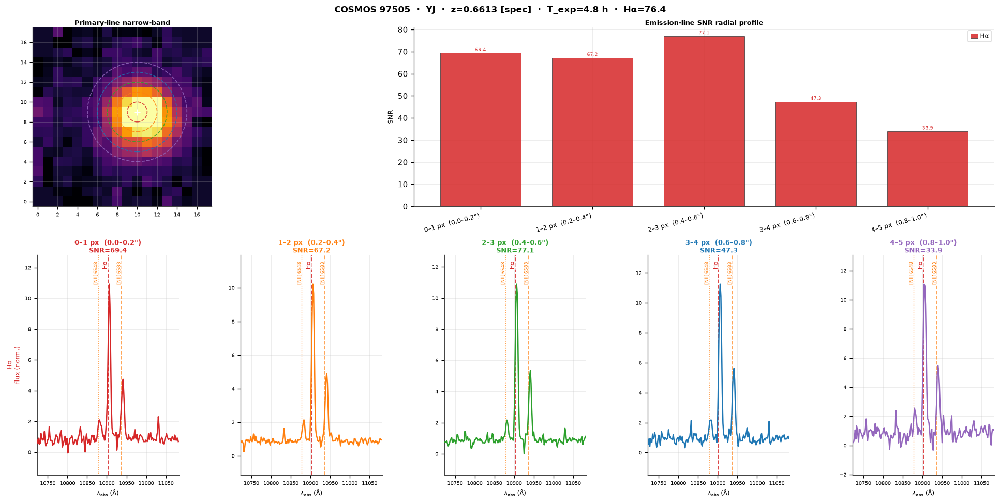

Saved → kmos_snr_annuli_detail_COSMOS_97505_YJ.pdf


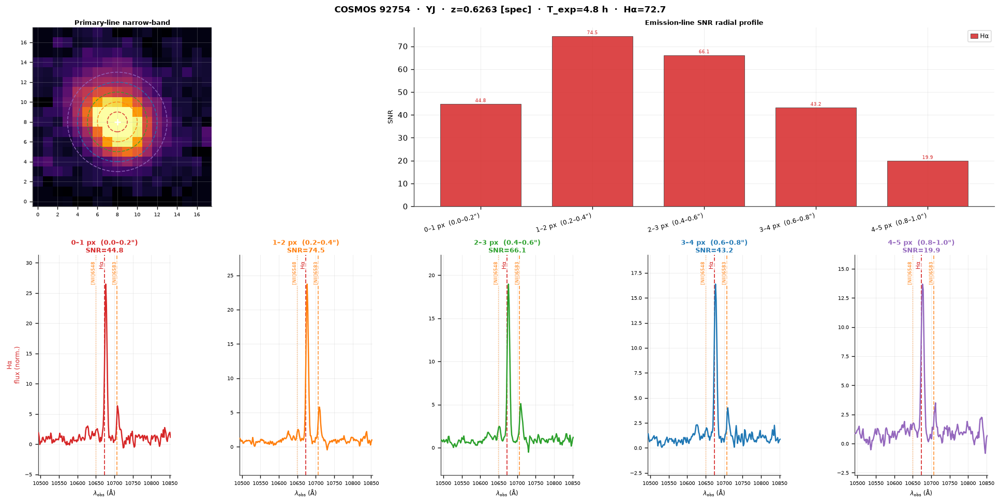

Saved → kmos_snr_annuli_detail_COSMOS_92754_YJ.pdf


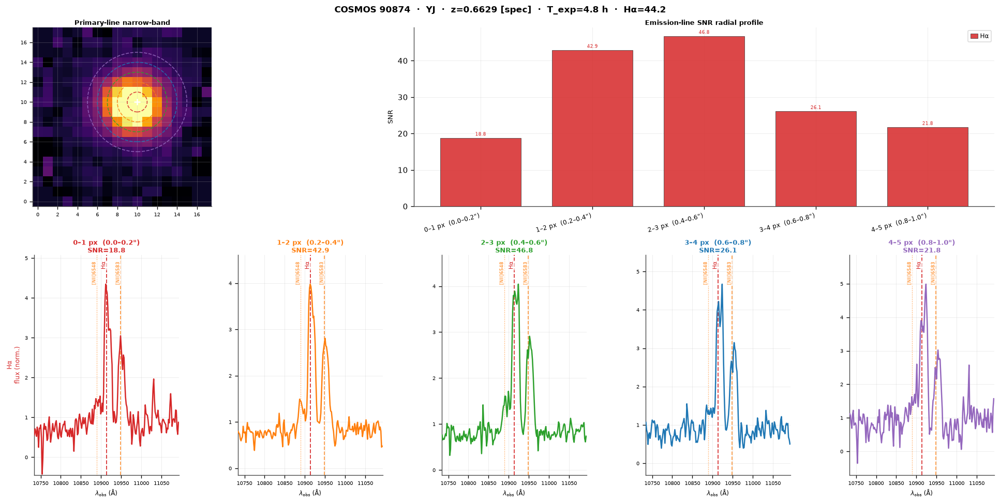

Saved → kmos_snr_annuli_detail_COSMOS_90874_YJ.pdf


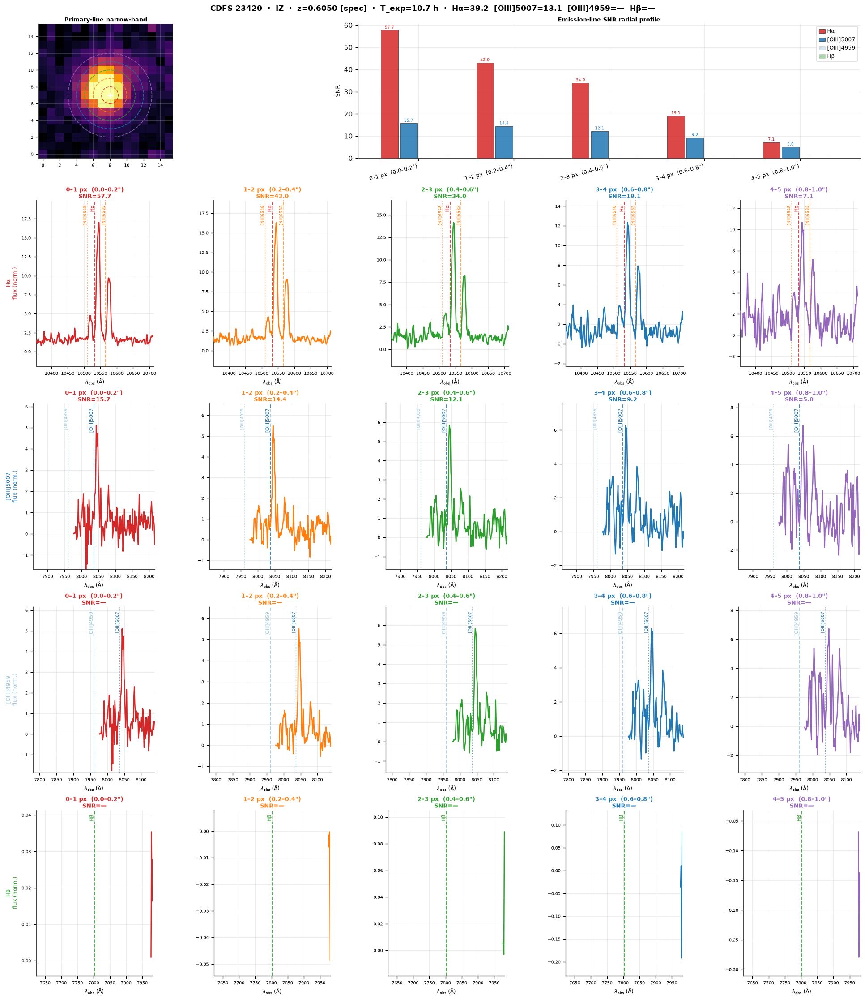

Saved → kmos_snr_annuli_detail_CDFS_23420_IZ.pdf


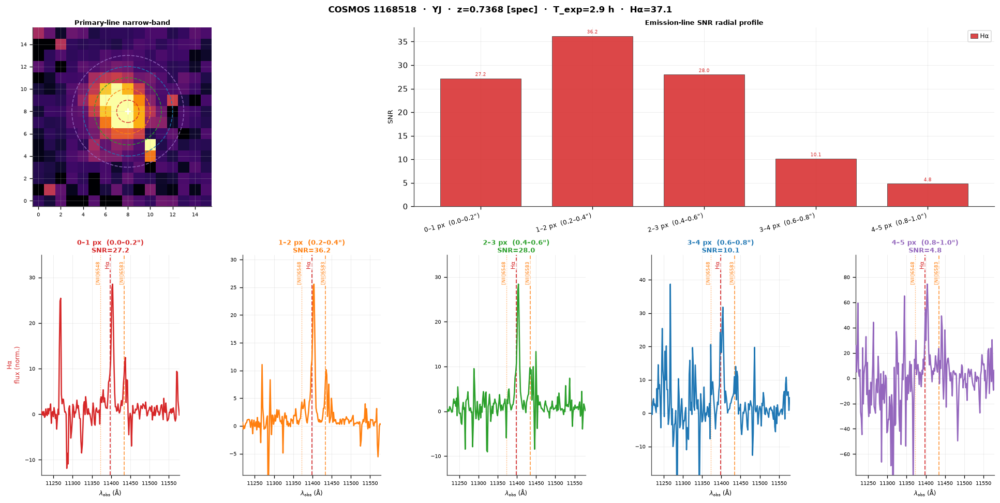

Saved → kmos_snr_annuli_detail_COSMOS_1168518_YJ.pdf


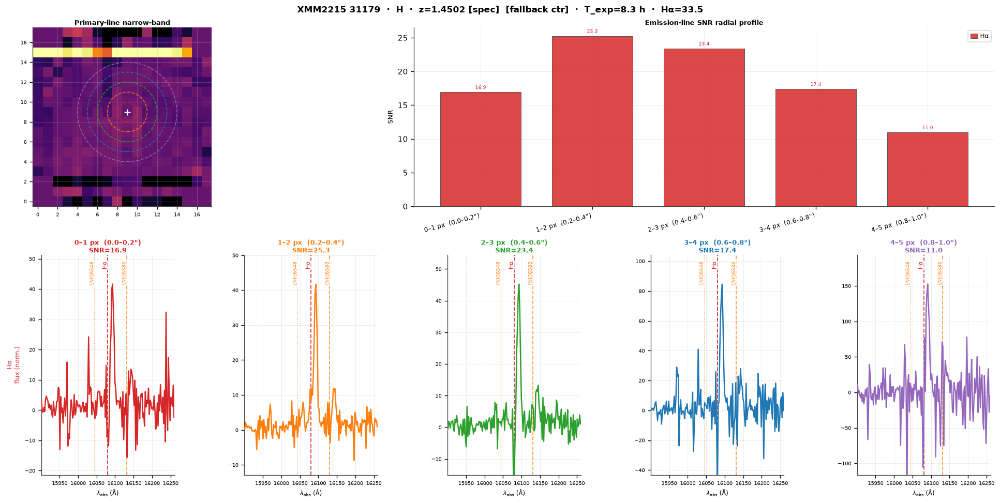

Saved → kmos_snr_annuli_detail_XMM2215_31179_H.pdf


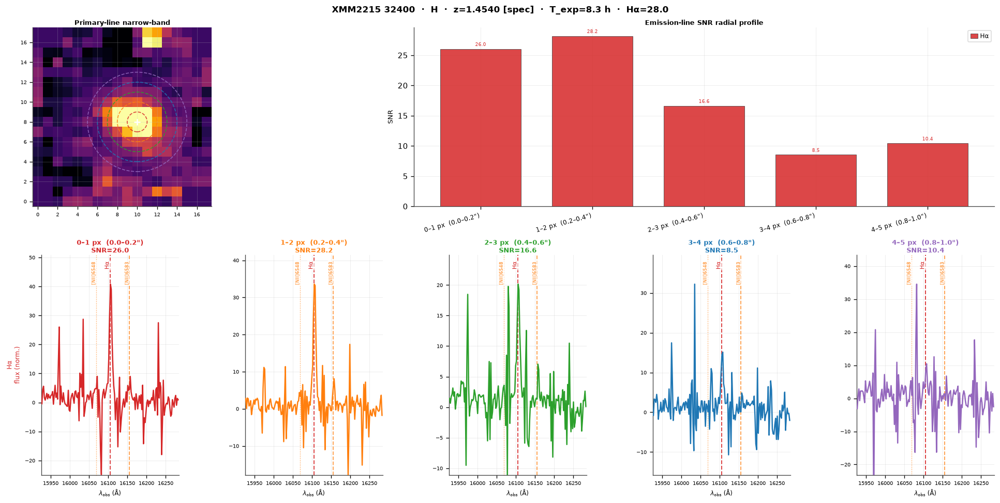

Saved → kmos_snr_annuli_detail_XMM2215_32400_H.pdf


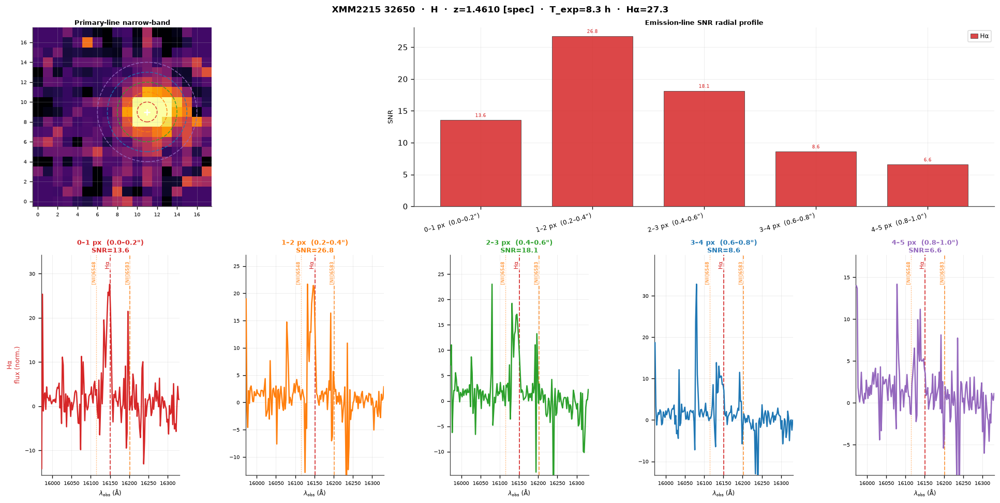

Saved → kmos_snr_annuli_detail_XMM2215_32650_H.pdf


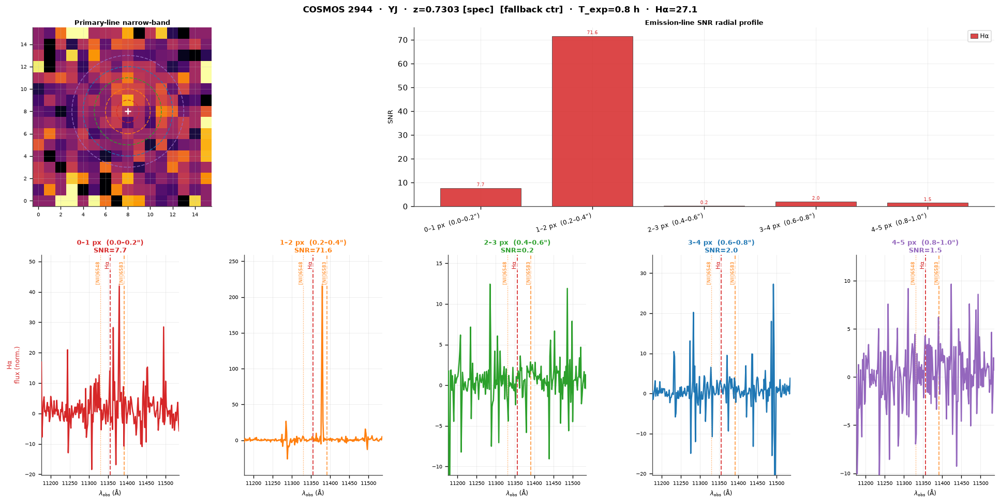

Saved → kmos_snr_annuli_detail_COSMOS_2944_YJ.pdf


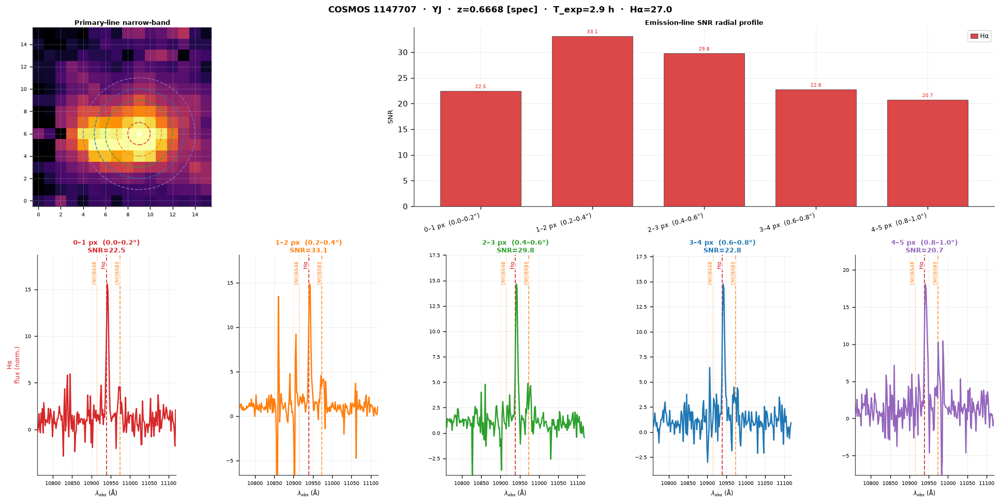

Saved → kmos_snr_annuli_detail_COSMOS_1147707_YJ.pdf


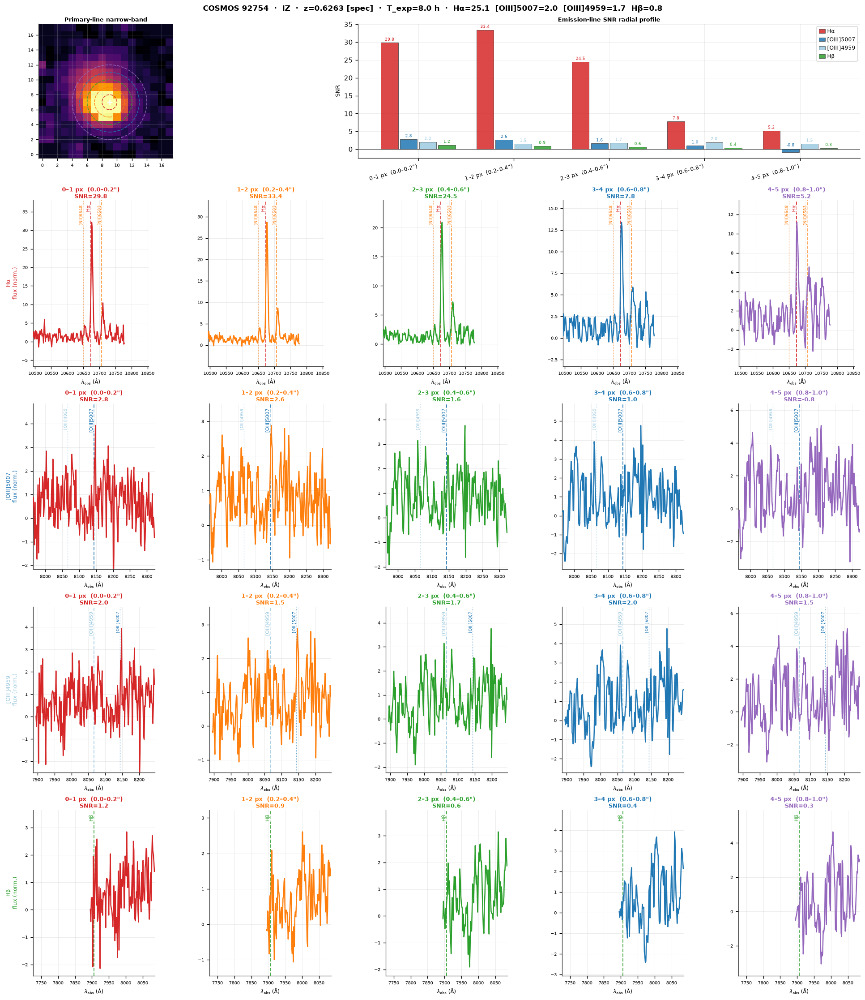

Saved → kmos_snr_annuli_detail_COSMOS_92754_IZ.pdf


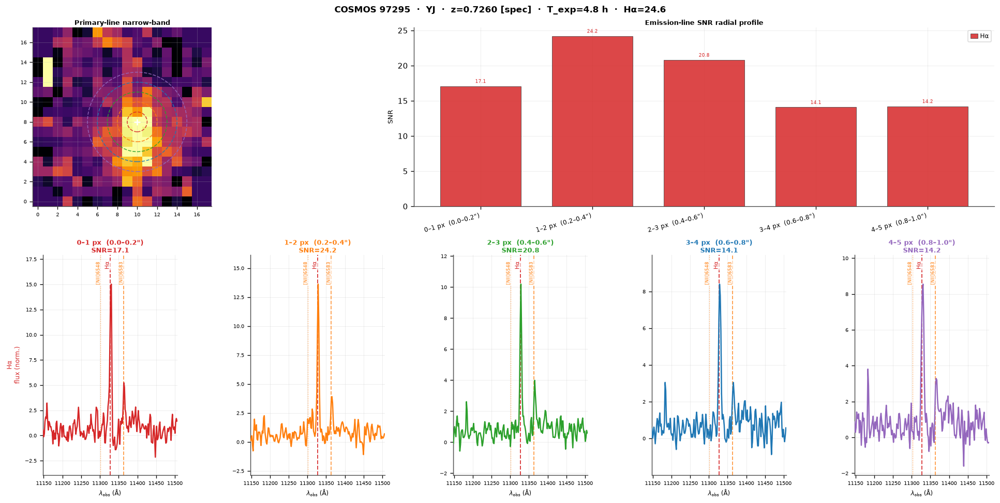

Saved → kmos_snr_annuli_detail_COSMOS_97295_YJ.pdf


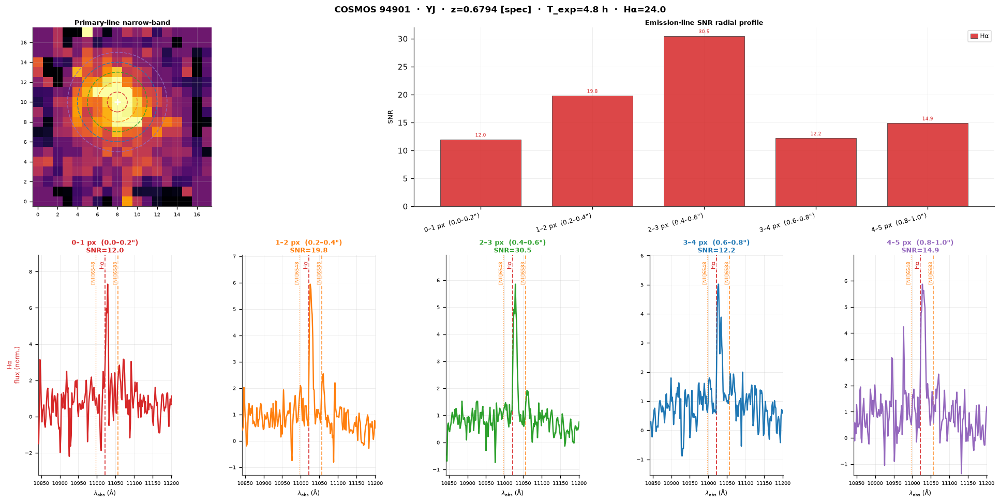

Saved → kmos_snr_annuli_detail_COSMOS_94901_YJ.pdf


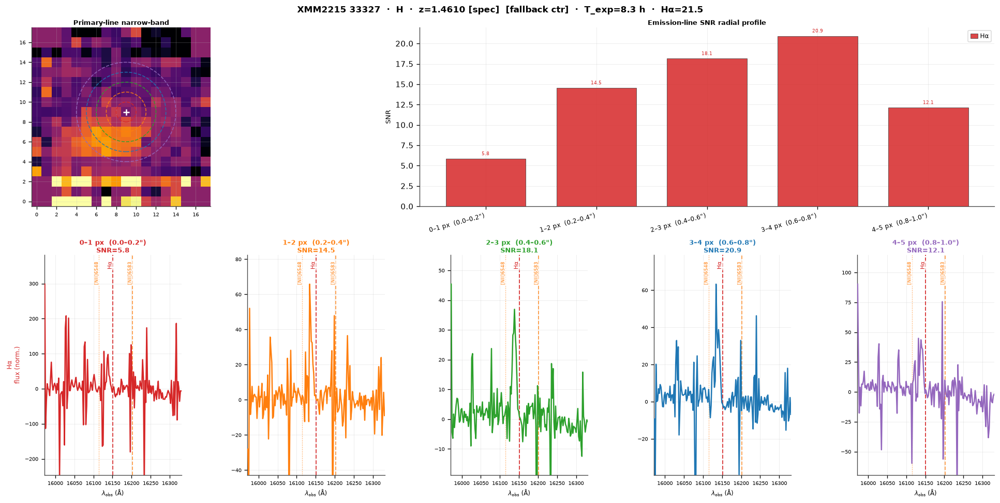

Saved → kmos_snr_annuli_detail_XMM2215_33327_H.pdf


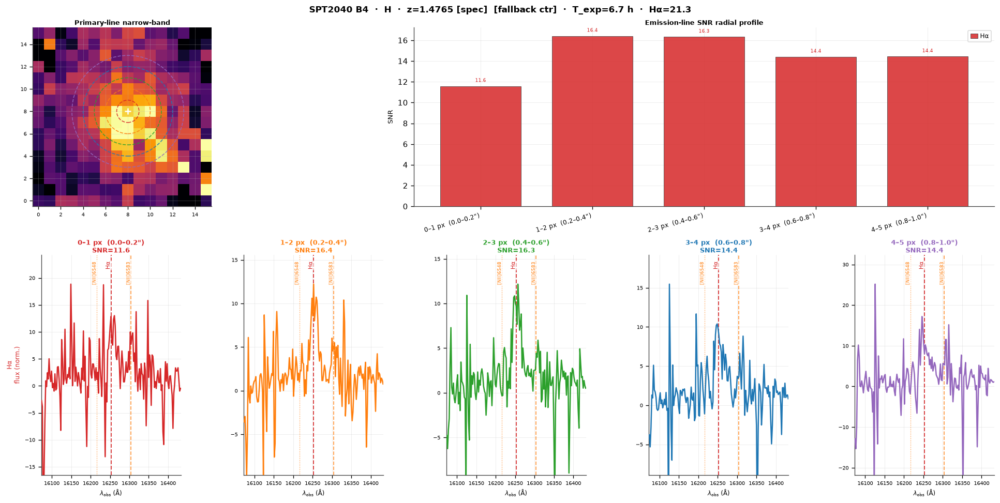

Saved → kmos_snr_annuli_detail_SPT2040_B4_H.pdf


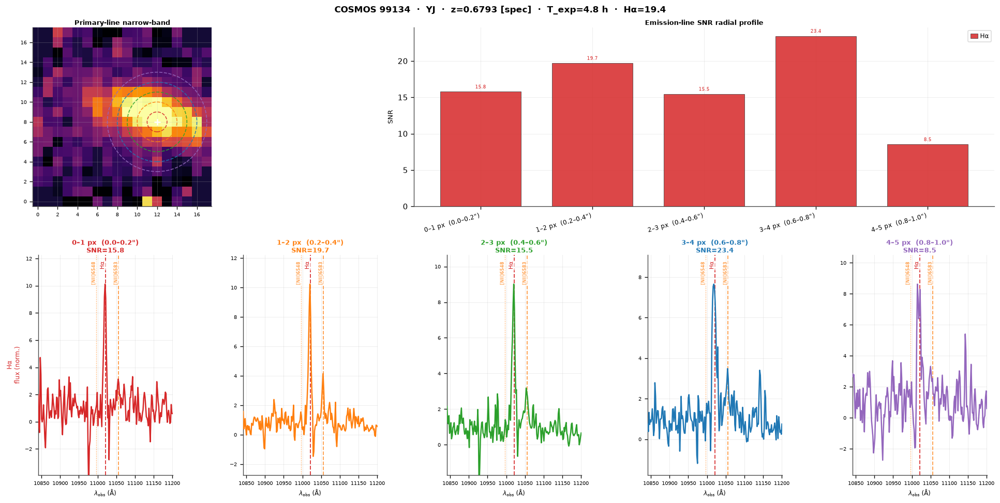

Saved → kmos_snr_annuli_detail_COSMOS_99134_YJ.pdf


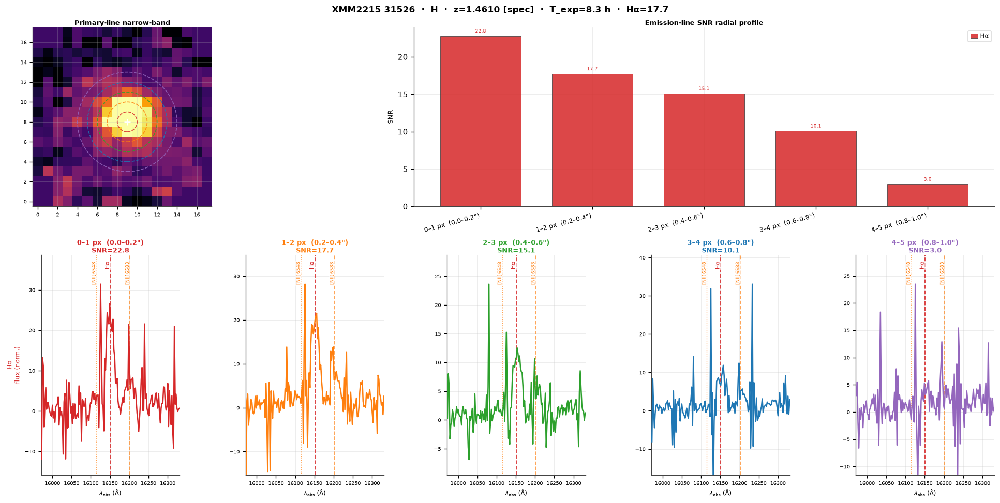

Saved → kmos_snr_annuli_detail_XMM2215_31526_H.pdf


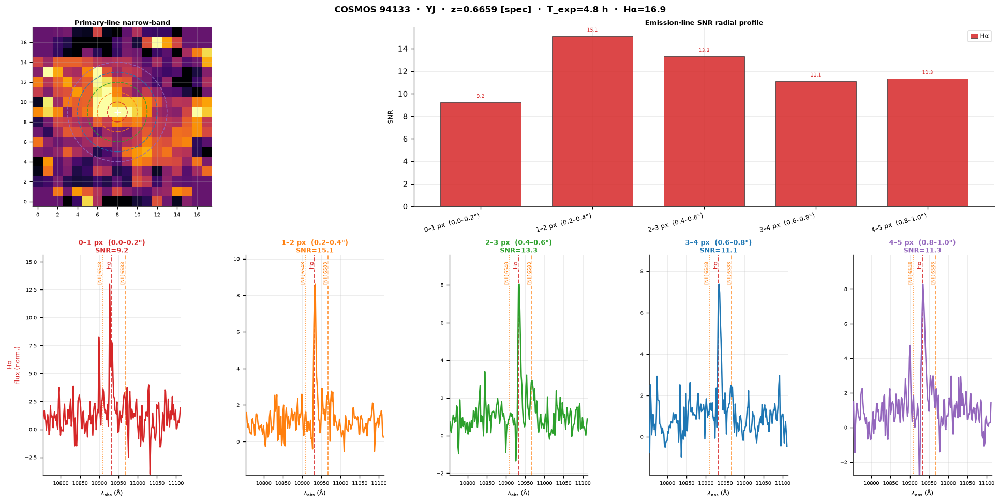

Saved → kmos_snr_annuli_detail_COSMOS_94133_YJ.pdf


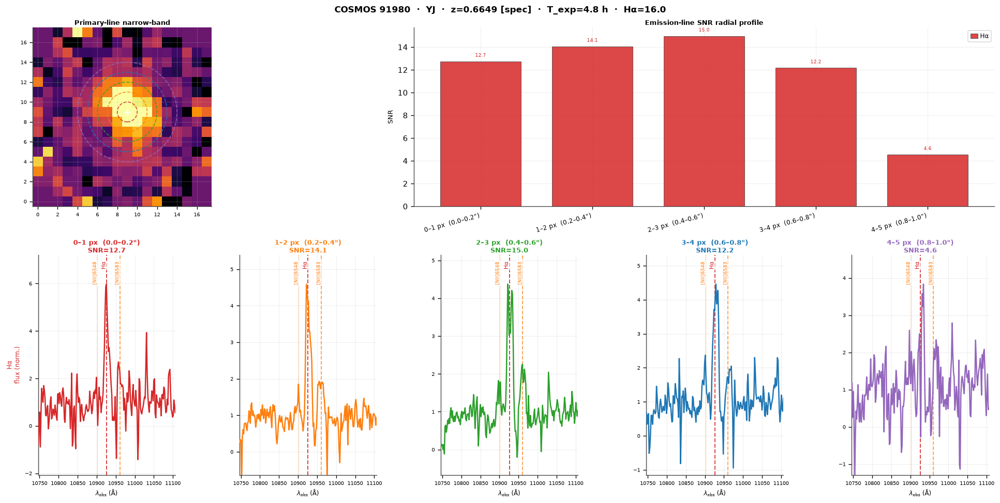

Saved → kmos_snr_annuli_detail_COSMOS_91980_YJ.pdf


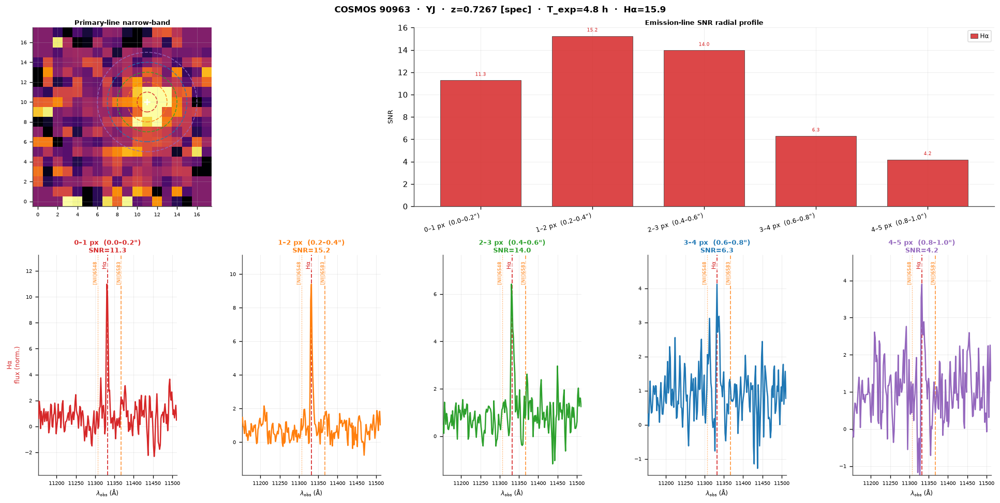

Saved → kmos_snr_annuli_detail_COSMOS_90963_YJ.pdf


In [8]:
top = detected[:TOP_DETAIL]

# Companion lines to mark in each line's spectrum panels
LINE_MARKERS = {
    "Hα":          {"[NII]6548": (0.65480, "#ff7f0e", 0.8, ":"),
                    "[NII]6583": (0.65835, "#ff7f0e", 1.1, "--")},
    "[OIII]5007":  {"[OIII]4959": (0.49598, "#9ecae1", 0.8, ":")},
    "[OIII]4959":  {"[OIII]5007": (0.50073, "#1f77b4", 0.8, ":")},
    "Hβ":          {},
}

if not top:
    print("No targets to display.")
else:
    for e, gal_color in zip(top, PALETTE):
        wave = e['wave']
        z    = e['z']

        # Lines detectable in this galaxy's wavelength range
        gal_lines = [
            (lbl, lrest, lcolor, lwh) for lbl, lrest, lcolor, lwh in EMISSION_LINES
            if wave.min() < lrest * (1.0 + z) < wave.max()
        ]
        if not gal_lines:
            continue

        n_spec_rows   = len(gal_lines)
        height_ratios = [1.5] + [1.8] * n_spec_rows
        fig = plt.figure(figsize=(16, 4.5 + n_spec_rows * 3.5), constrained_layout=True)
        fb  = "  [fallback ctr]" if e.get('fallback') else ''
        sbl = e['snr_by_line']
        snr_parts = [
            f"{lbl}={sbl.get(lbl, np.nan):.1f}" if np.isfinite(sbl.get(lbl, np.nan))
            else f"{lbl}=—"
            for lbl, *_ in gal_lines
        ]
        fig.suptitle(
            f"{e['field']} {e['tid']}  ·  {e['band']}  ·  z={z:.4f} [{e['z_type']}]{fb}  ·  "
            f"T_exp={_texp_str(e['total_exptime_s'])}  ·  " + "  ".join(snr_parts),
            fontsize=10, fontweight='bold',
        )

        outer = gridspec.GridSpec(1 + n_spec_rows, 1, figure=fig,
                                  height_ratios=height_ratios, hspace=0.45)

        # ── Row 0: image + grouped SNR profile ───────────────────────────────
        top_inner = gridspec.GridSpecFromSubplotSpec(
            1, 2, subplot_spec=outer[0], width_ratios=[1, 2.5], wspace=0.30)
        ax_im  = fig.add_subplot(top_inner[0])
        ax_snr = fig.add_subplot(top_inner[1])

        ha_im  = e.get('ha_image')
        cy, cx = e['ctr_ha']
        if ha_im is not None and np.isfinite(ha_im).any():
            fin = ha_im[np.isfinite(ha_im)]
            ax_im.imshow(ha_im, origin='lower', aspect='equal', cmap='inferno',
                         vmin=np.nanpercentile(fin, 5), vmax=np.nanpercentile(fin, 97))
        else:
            ax_im.set_facecolor('#111')
        for i, r_out in enumerate(ANNULUS_EDGES[1:]):
            ax_im.add_patch(plt.Circle((cx, cy), r_out,
                                       fill=False, edgecolor=ANNULUS_COLORS[i],
                                       lw=1.0, ls='--', alpha=0.85))
        ax_im.plot(cx, cy, '+', ms=7, mew=1.5, color='white', zorder=5)
        ax_im.set_title("Primary-line narrow-band", fontsize=8, pad=3)
        ax_im.tick_params(labelsize=6)

        n_gal  = len(gal_lines)
        bar_w  = 0.8 / max(n_gal, 1)
        xs     = np.arange(n_ann)
        for li, (lbl, lrest, lcolor, lwh) in enumerate(gal_lines):
            snrs   = e['ann_snrs_by_line'].get(lbl, [np.nan]*n_ann)
            offset = (li - (n_gal - 1) / 2) * bar_w
            vals   = [v if np.isfinite(v) else 0 for v in snrs]
            bars   = ax_snr.bar(xs + offset, vals, bar_w * 0.9,
                                color=lcolor, alpha=0.85, edgecolor='#333', lw=0.5,
                                label=lbl, zorder=3)
            for bi, v in enumerate(snrs):
                if not np.isfinite(v):
                    bars[bi].set_hatch('//')
                    bars[bi].set_edgecolor('#aaa')
                    bars[bi].set_alpha(0.4)
                txt  = f"{v:.1f}" if np.isfinite(v) else "—"
                ypos = (v + 0.3) if (np.isfinite(v) and v > 0) else 0.5
                ax_snr.text(xs[bi] + offset, ypos, txt, ha='center', va='bottom',
                            fontsize=5.5, color=lcolor if np.isfinite(v) else '#aaa')
        ax_snr.axhline(0, color='#555', lw=0.6)
        ax_snr.set_xticks(xs)
        ax_snr.set_xticklabels(
            [f"{edges[i]}–{edges[i+1]} px  ({edges[i]*SPAXEL_SCALE:.1f}–"
             f"{edges[i+1]*SPAXEL_SCALE:.1f}\")" for i in range(n_ann)],
            fontsize=7, rotation=15, ha='right',
        )
        ax_snr.set_ylabel("SNR", fontsize=8)
        ax_snr.set_title("Emission-line SNR radial profile", fontsize=8, pad=3)
        ax_snr.legend(fontsize=7, loc='upper right', framealpha=0.7,
                      handlelength=1.2, handletextpad=0.4)

        # ── Rows 1+: per-line × per-annulus spectra ───────────────────────────
        for row_i, (lbl, lrest, lcolor, lwh) in enumerate(gal_lines):
            lam_obs = lrest * (1.0 + z)
            wlo = lam_obs - ZOOM_HALF
            whi = lam_obs + ZOOM_HALF
            mask = (wave >= wlo) & (wave <= whi)

            bot_inner = gridspec.GridSpecFromSubplotSpec(
                1, n_ann, subplot_spec=outer[1 + row_i], wspace=0.25)

            companions = LINE_MARKERS.get(lbl, {})

            for ai in range(n_ann):
                ax        = fig.add_subplot(bot_inner[ai])
                spec      = e['ann_specs'][ai]
                snrs      = e['ann_snrs_by_line'].get(lbl, [np.nan]*n_ann)
                snr_v     = snrs[ai]
                ann_color = ANNULUS_COLORS[ai]

                if mask.any() and np.isfinite(spec[mask]).any():
                    ax.plot(wave[mask] * 1e4, spec[mask], color=ann_color, lw=1.5, zorder=3)
                else:
                    ax.text(0.5, 0.5, 'no signal', ha='center', va='center',
                            transform=ax.transAxes, fontsize=8, color='#aaa', style='italic')

                ax.axvline(lam_obs * 1e4, color=lcolor, lw=1.2, ls='--', alpha=0.85, zorder=2)
                ax.text(lam_obs * 1e4, 0.97, lbl,
                        transform=ax.get_xaxis_transform(),
                        rotation=90, ha='right', va='top', fontsize=6.5, color=lcolor,
                        bbox=dict(fc='white', ec='none', alpha=0.6, pad=1))

                for cname, (crest, cc, clw, cls) in companions.items():
                    co = crest * (1.0 + z)
                    if wlo <= co <= whi:
                        ax.axvline(co * 1e4, color=cc, lw=clw, ls=cls, alpha=0.75, zorder=2)
                        ax.text(co * 1e4, 0.97, cname,
                                transform=ax.get_xaxis_transform(),
                                rotation=90, ha='right', va='top', fontsize=5.5, color=cc,
                                bbox=dict(fc='white', ec='none', alpha=0.6, pad=1))

                vis = spec[mask] if mask.any() else np.array([])
                fv  = vis[np.isfinite(vis)]
                if fv.size:
                    ylo_ = np.nanpercentile(fv, 2)
                    yhi_ = np.nanmax(fv)
                    pad  = 0.18 * max(yhi_ - ylo_, 1e-6)
                    ax.set_ylim(ylo_ - pad, yhi_ + pad)
                ax.set_xlim(wlo * 1e4, whi * 1e4)
                ax.tick_params(labelsize=6)
                ax.set_xlabel(r"$\lambda_{\rm obs}$ (Å)", fontsize=7)
                snr_s = f"SNR={snr_v:.1f}" if np.isfinite(snr_v) else "SNR=—"
                ax.set_title(
                    f"{edges[ai]}–{edges[ai+1]} px  "
                    f"({edges[ai]*SPAXEL_SCALE:.1f}–{edges[ai+1]*SPAXEL_SCALE:.1f}\")\n{snr_s}",
                    fontsize=7.5, color=ann_color, pad=3,
                )
                if ai == 0:
                    ax.set_ylabel(f"{lbl}\nflux (norm.)", fontsize=7, color=lcolor)

        fname = f"kmos_snr_annuli_detail_{e['field']}_{e['tid']}_{e['band']}.pdf"
        plt.savefig(fname, bbox_inches='tight')
        plt.show()
        print(f"Saved → {fname}")

## Detail view — [OIII] / Hβ galaxies (no Hα in range)

Galaxies where Hα falls **outside** the observed wavelength range — typically
IZ-band targets at z ≈ 0.6–0.75 or YJ-band targets at z ≈ 1.45 where only
[OIII]5007, [OIII]4959 and Hβ are covered.  Same layout as the detail section above.

Galaxies with OIII/Hβ but no Hα in range: 137


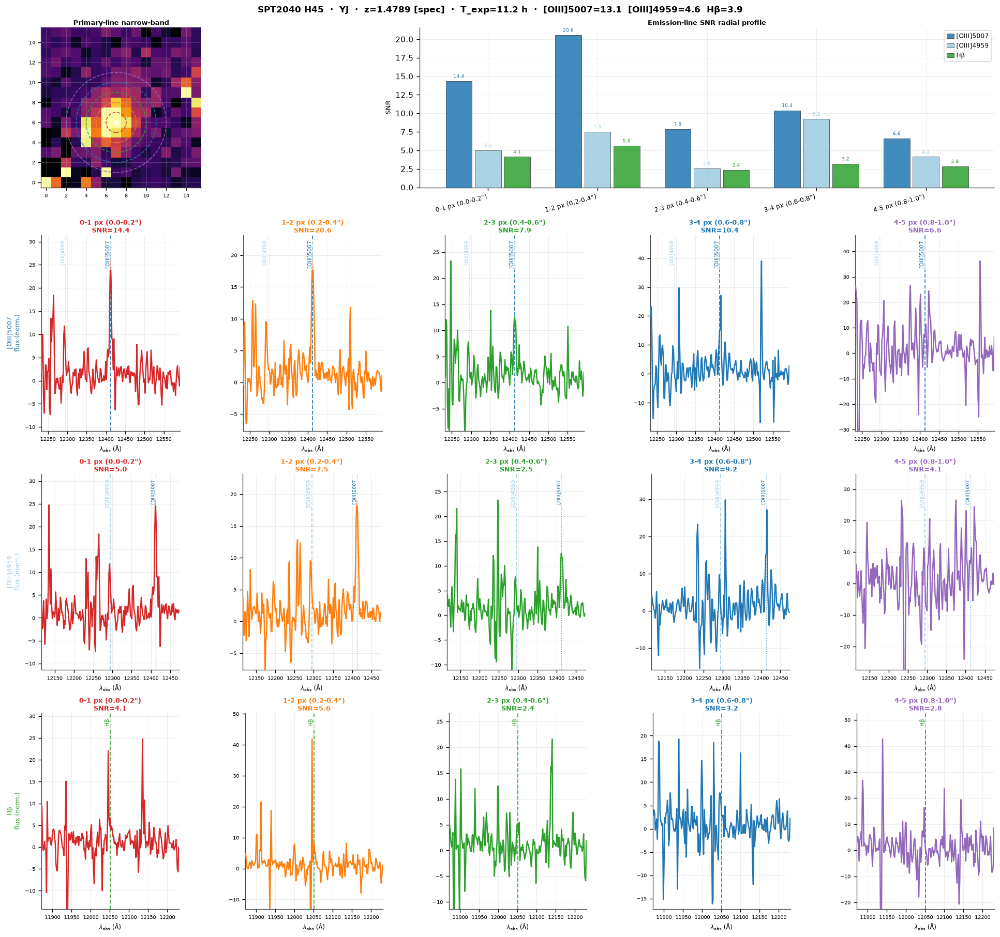

Saved → kmos_snr_annuli_oiii_detail_SPT2040_H45_YJ.pdf


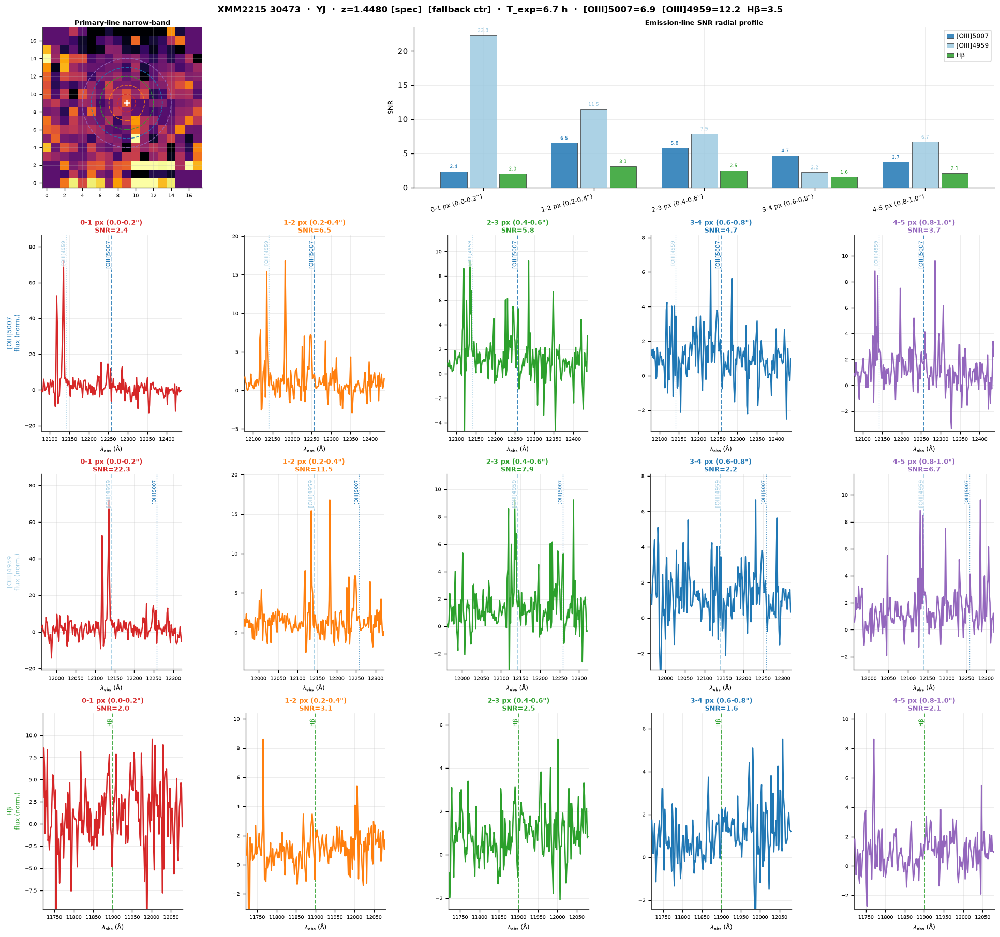

Saved → kmos_snr_annuli_oiii_detail_XMM2215_30473_YJ.pdf


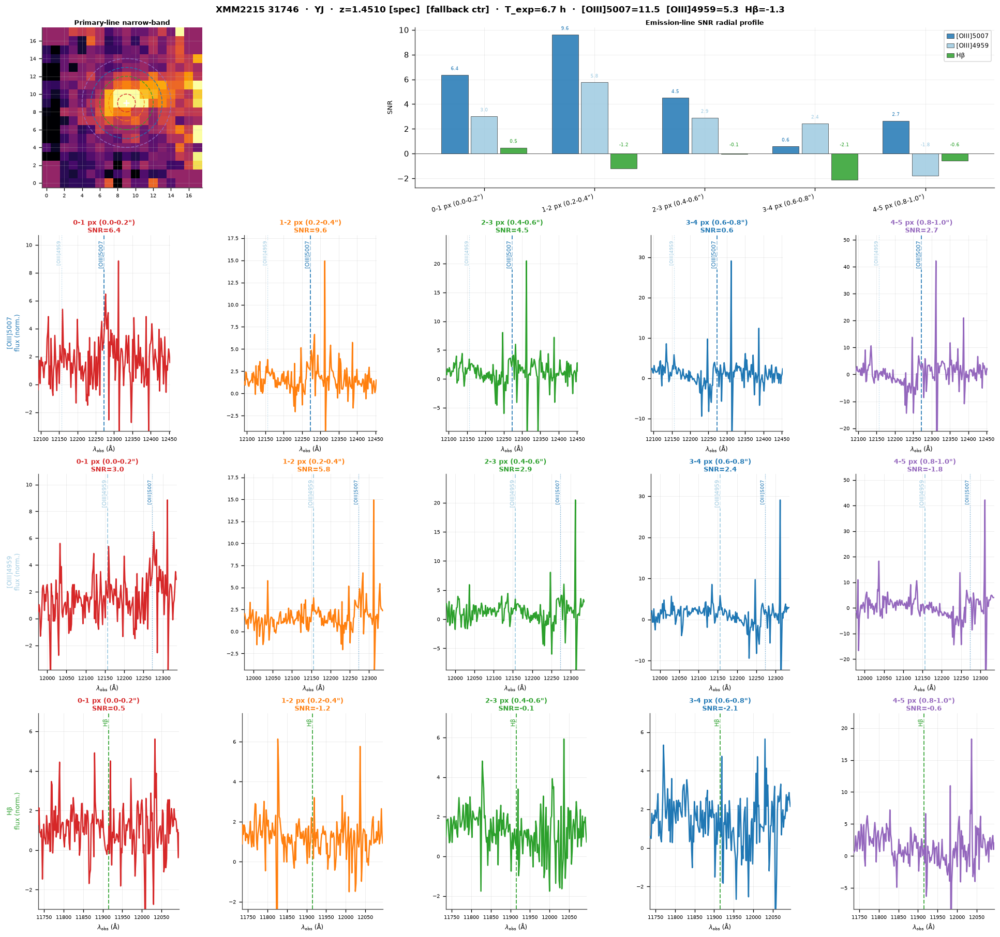

Saved → kmos_snr_annuli_oiii_detail_XMM2215_31746_YJ.pdf


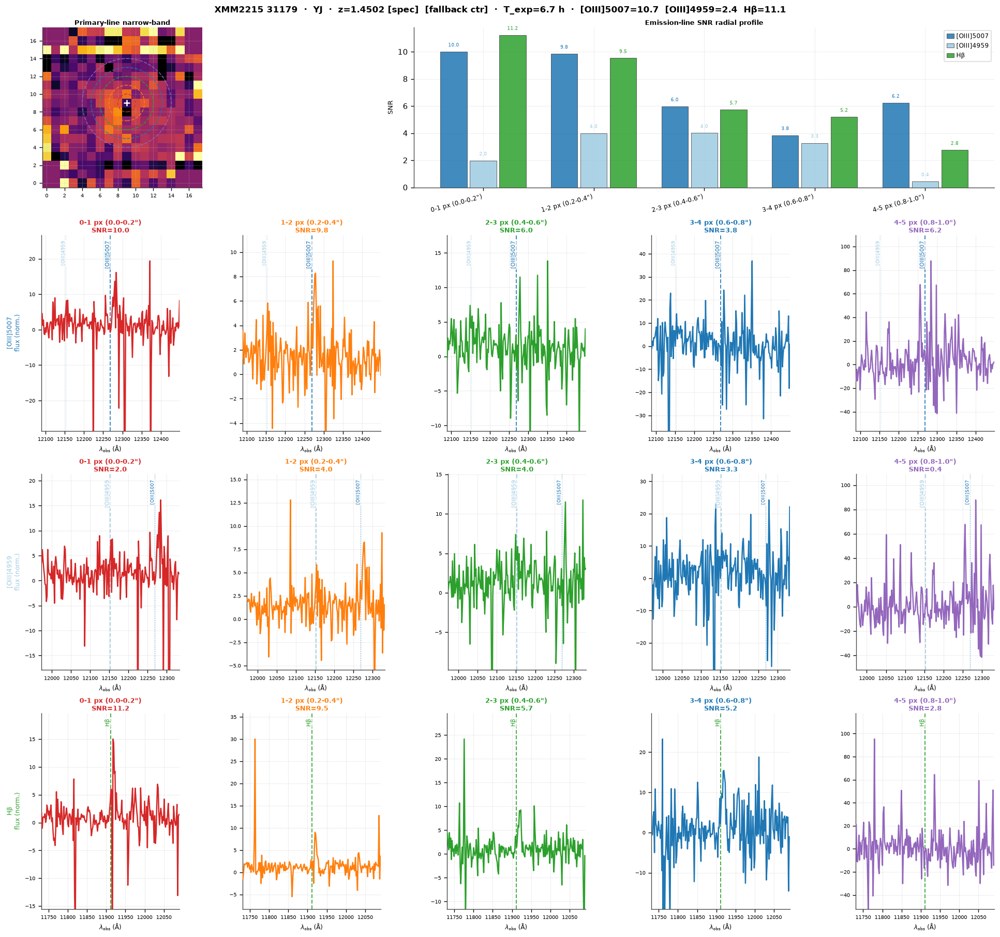

Saved → kmos_snr_annuli_oiii_detail_XMM2215_31179_YJ.pdf


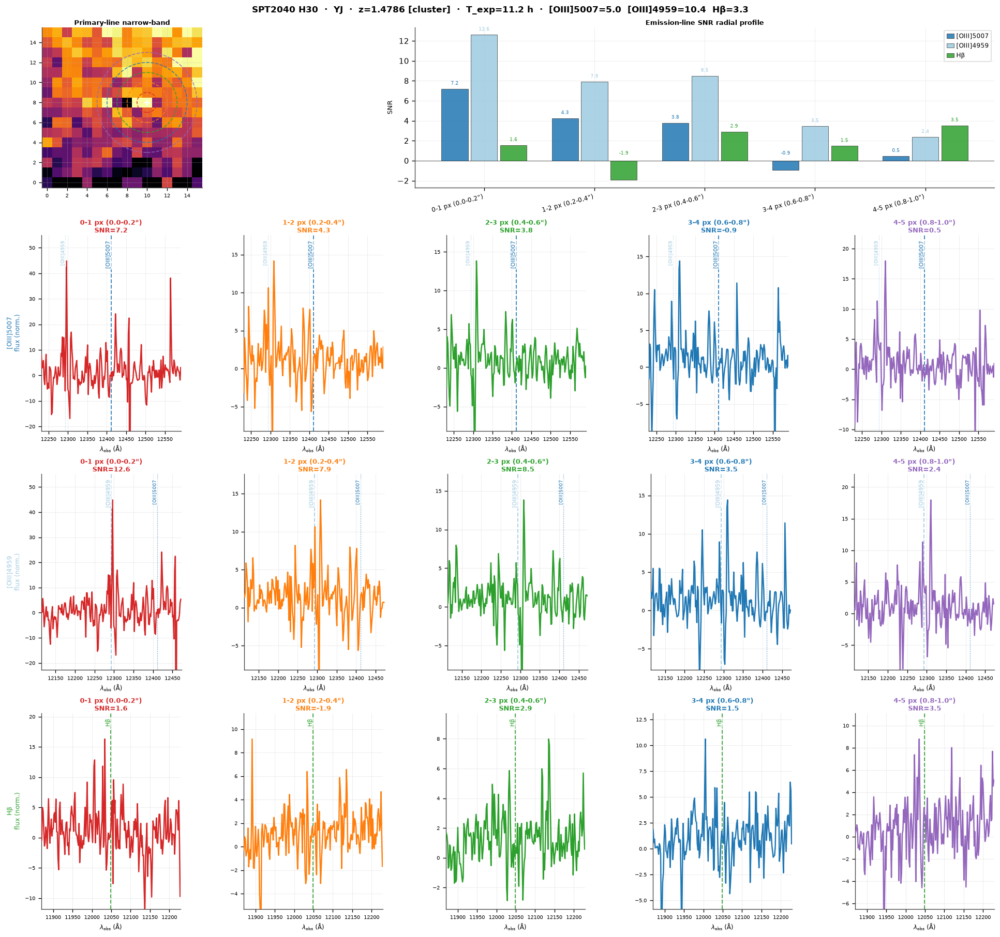

Saved → kmos_snr_annuli_oiii_detail_SPT2040_H30_YJ.pdf


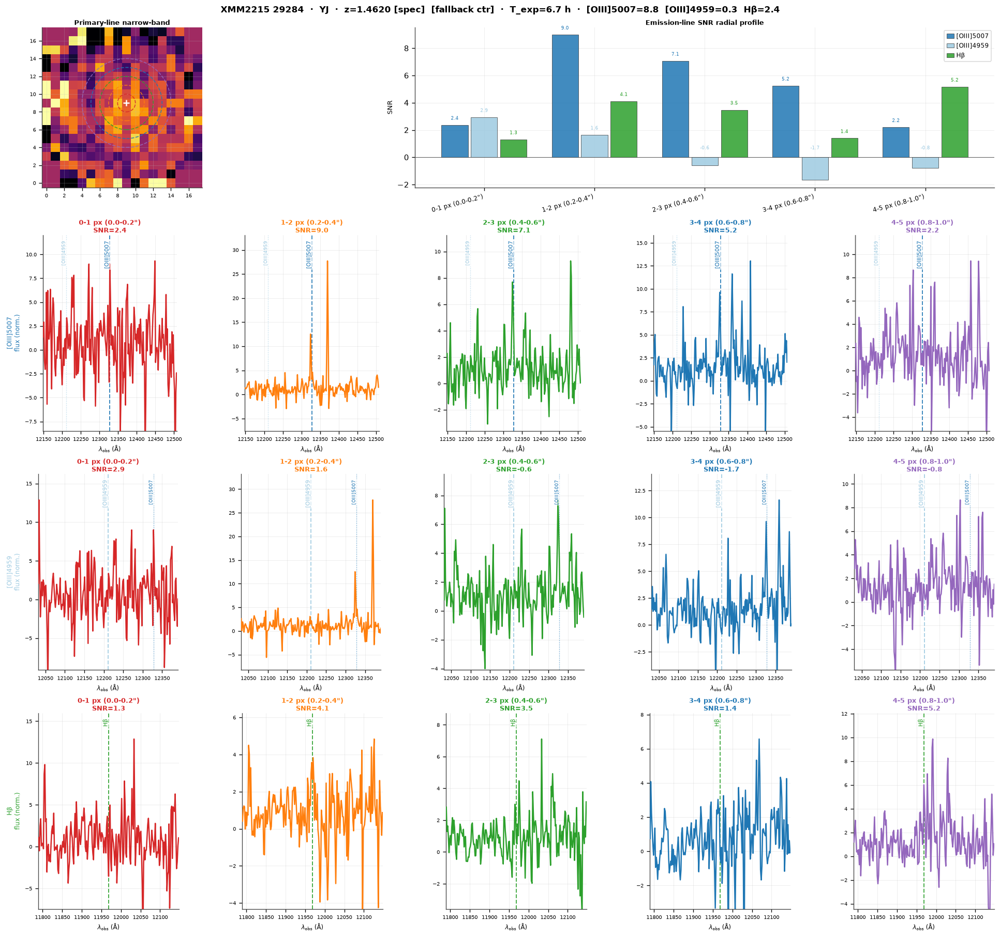

Saved → kmos_snr_annuli_oiii_detail_XMM2215_29284_YJ.pdf


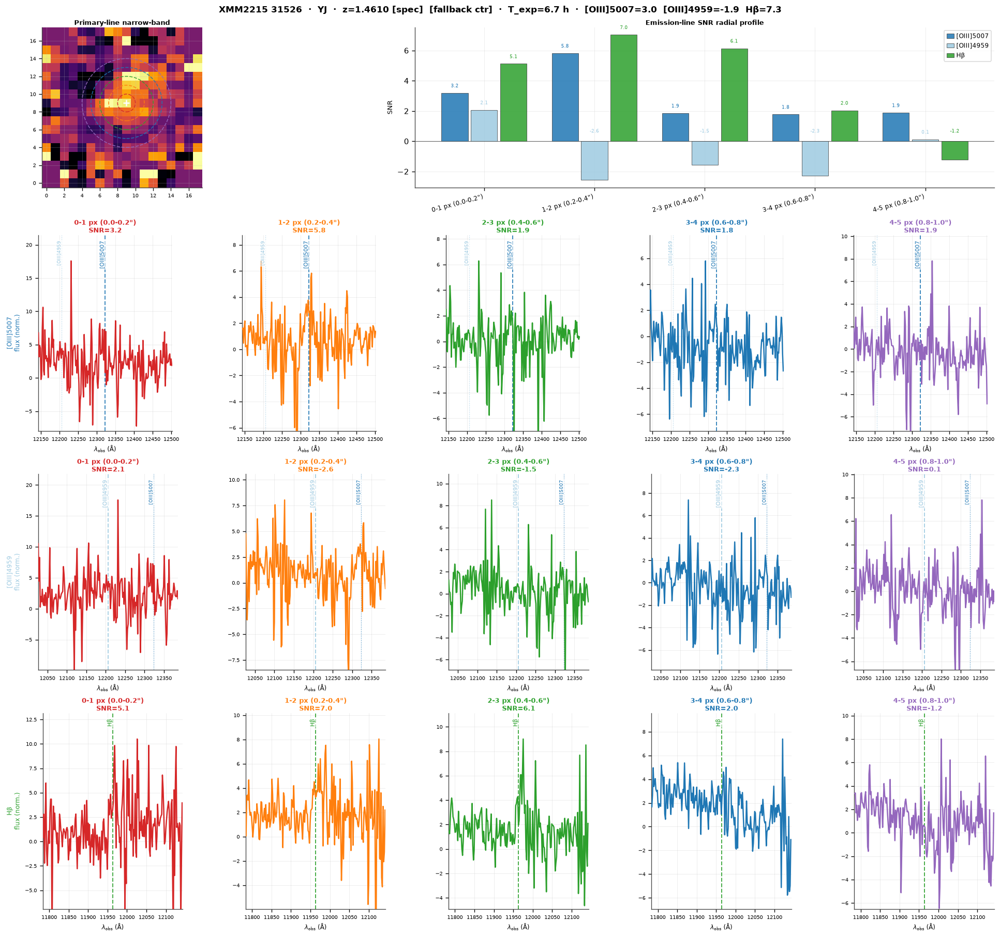

Saved → kmos_snr_annuli_oiii_detail_XMM2215_31526_YJ.pdf


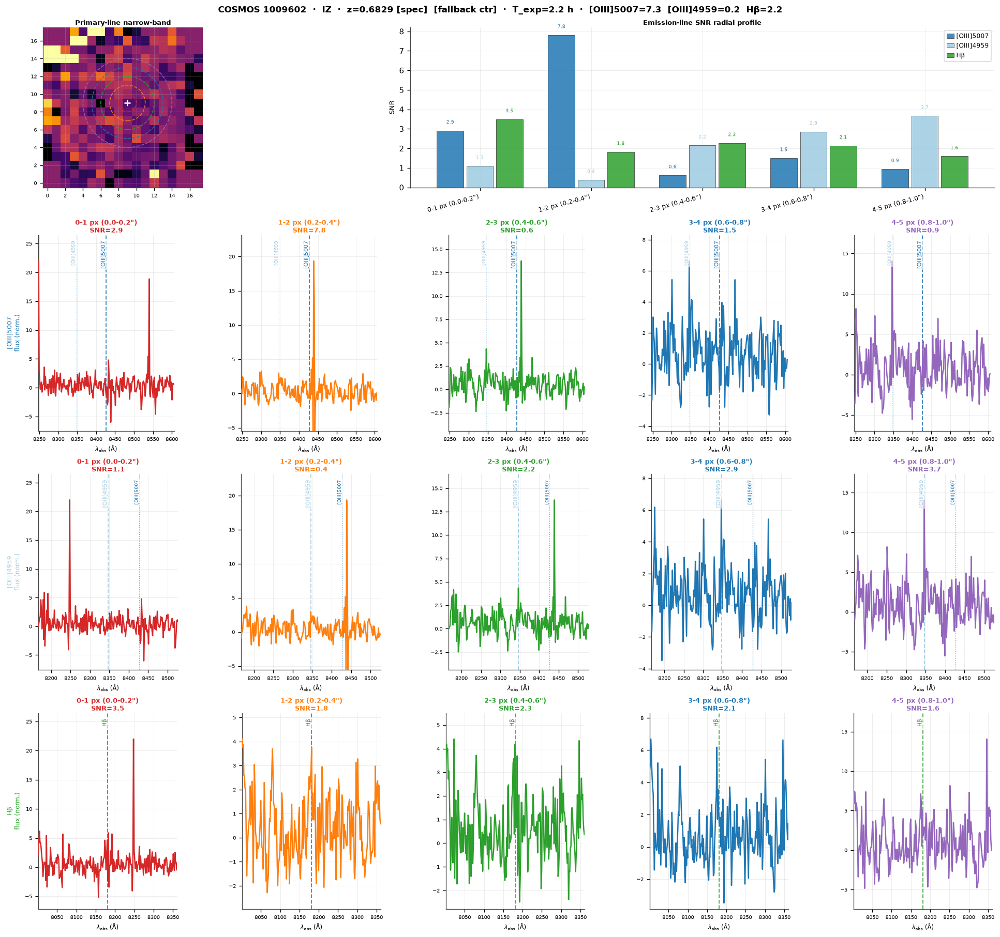

Saved → kmos_snr_annuli_oiii_detail_COSMOS_1009602_IZ.pdf


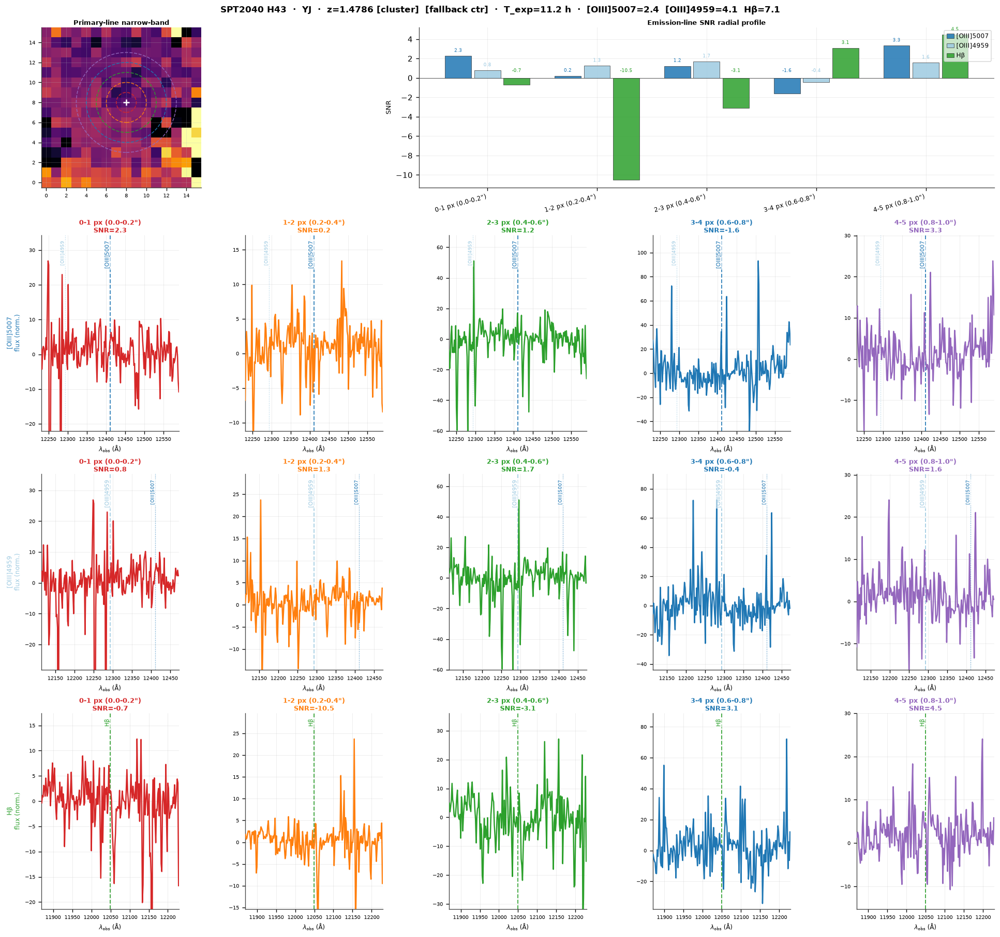

Saved → kmos_snr_annuli_oiii_detail_SPT2040_H43_YJ.pdf


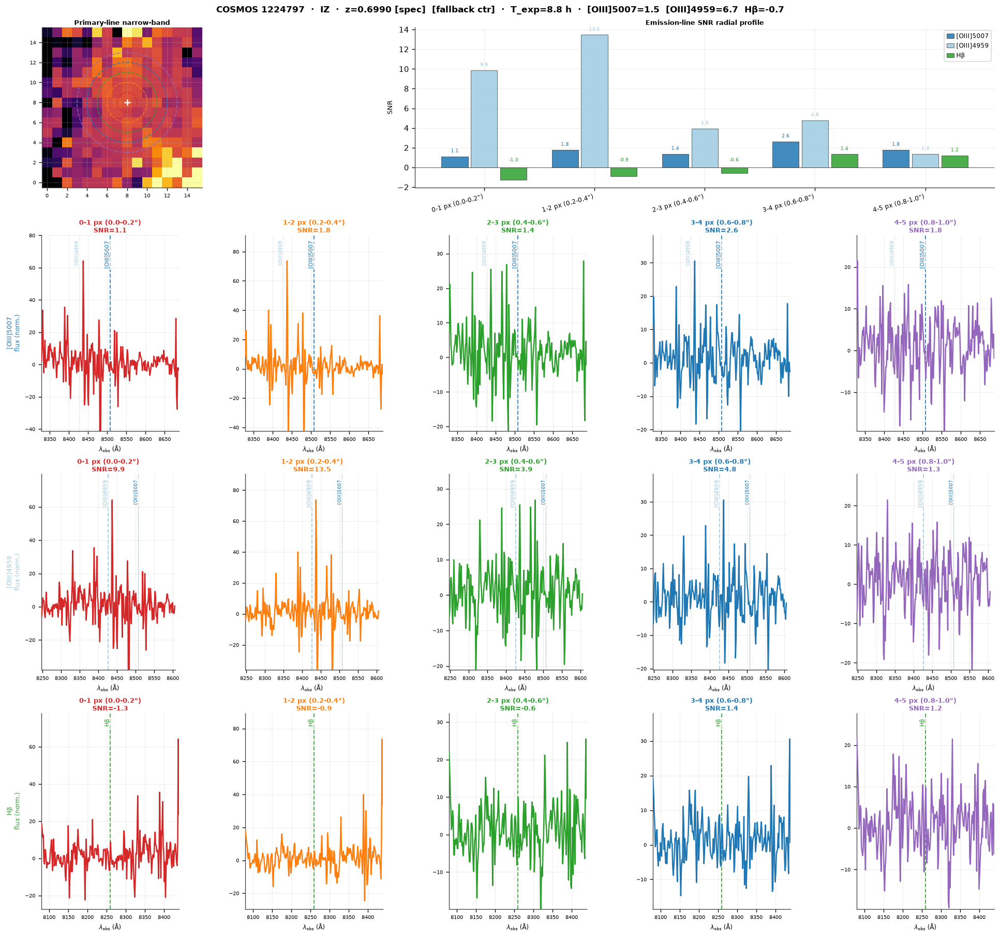

Saved → kmos_snr_annuli_oiii_detail_COSMOS_1224797_IZ.pdf


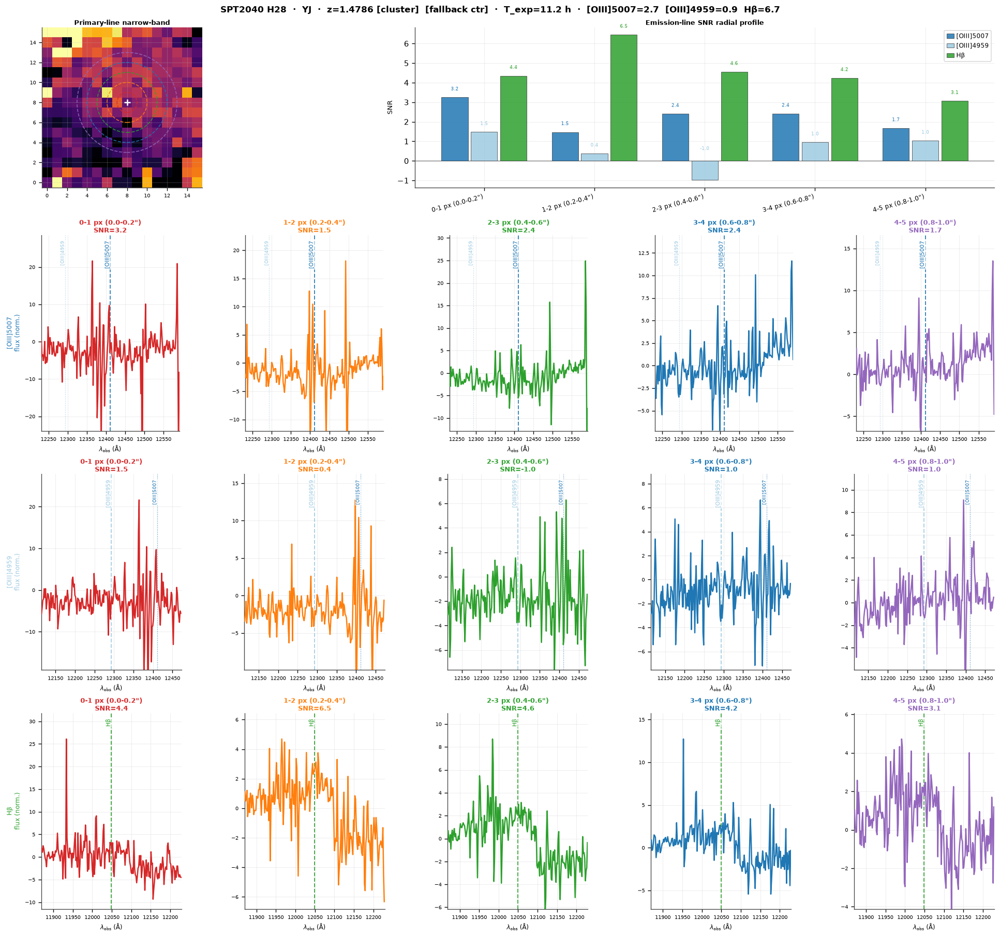

Saved → kmos_snr_annuli_oiii_detail_SPT2040_H28_YJ.pdf


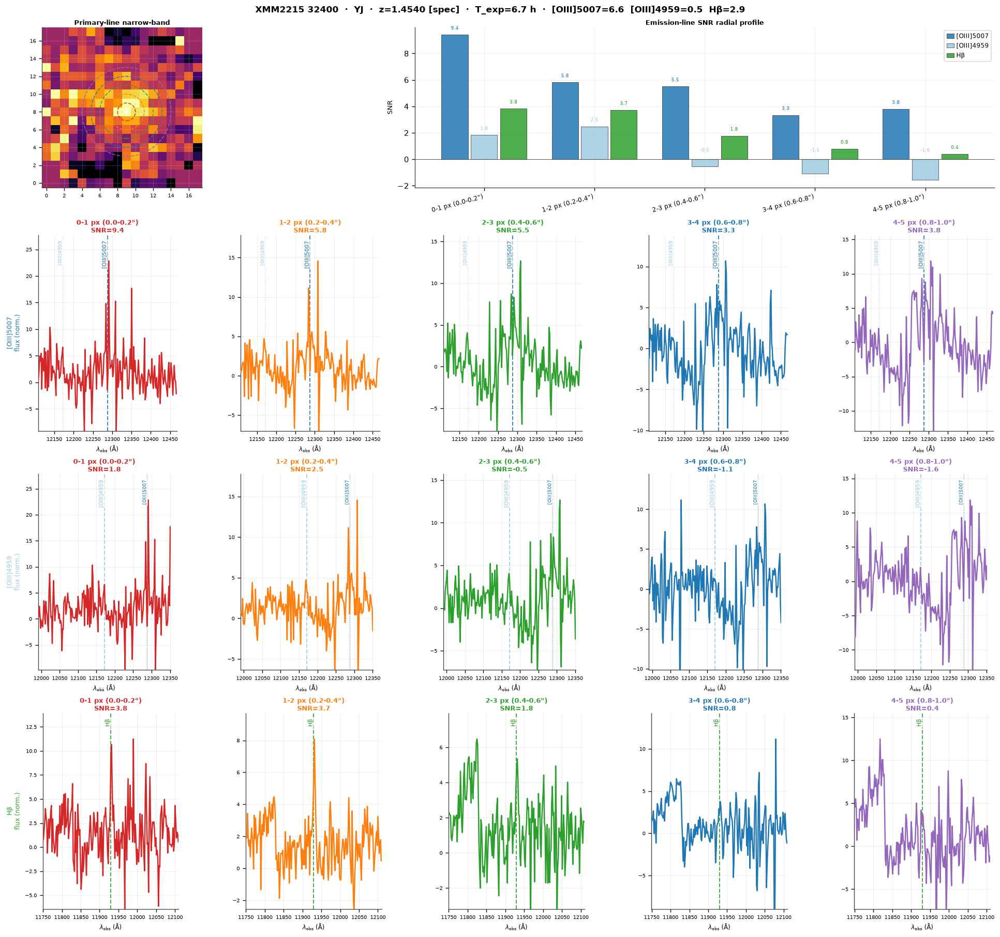

Saved → kmos_snr_annuli_oiii_detail_XMM2215_32400_YJ.pdf


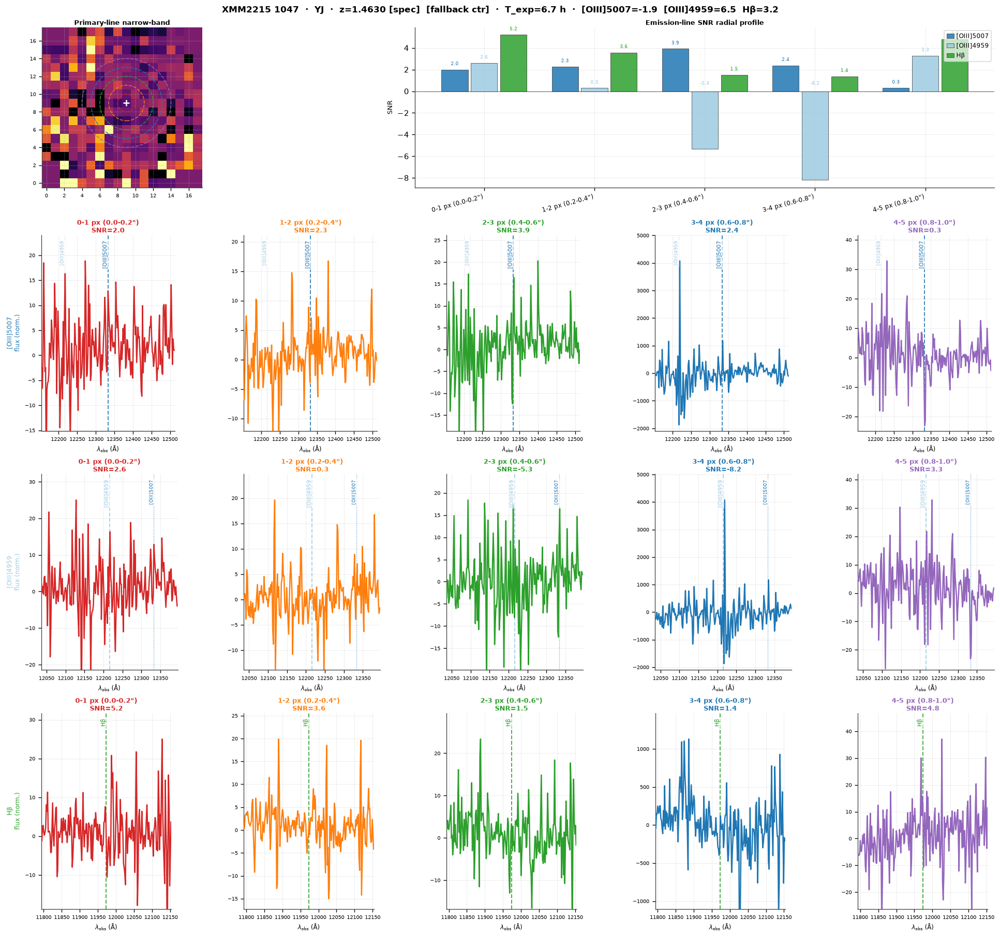

Saved → kmos_snr_annuli_oiii_detail_XMM2215_1047_YJ.pdf


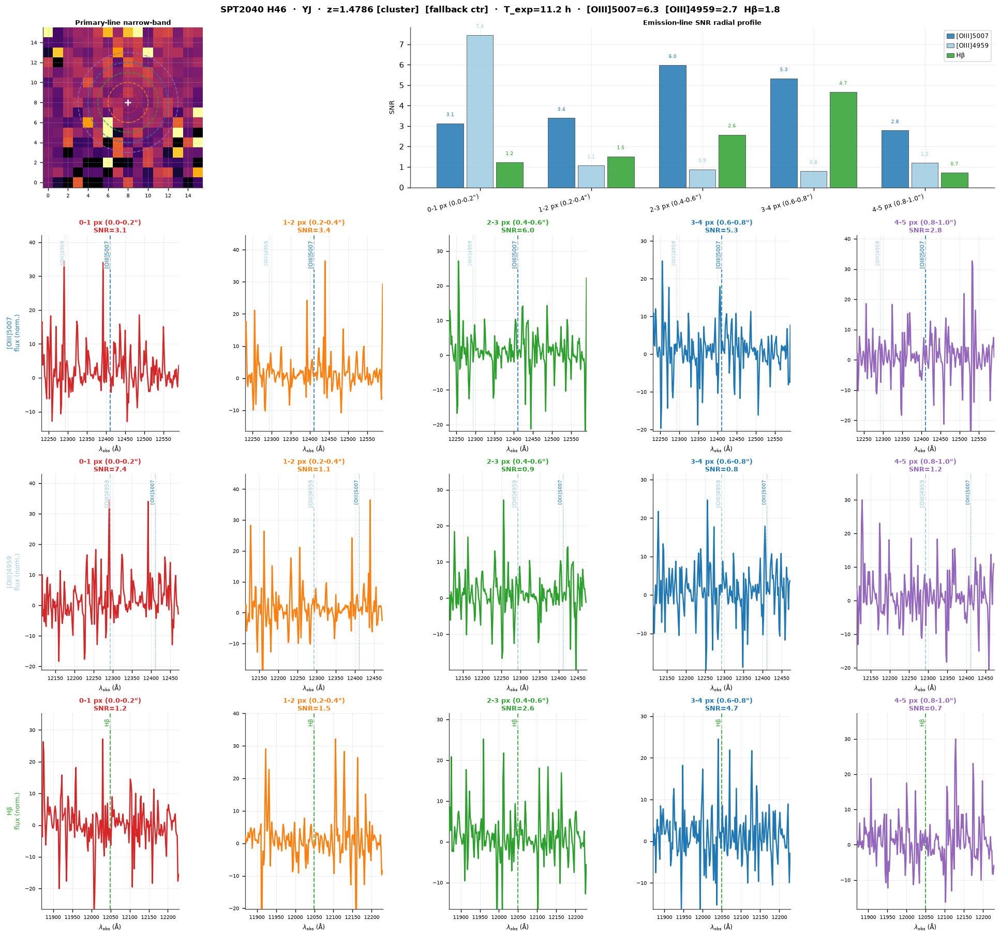

Saved → kmos_snr_annuli_oiii_detail_SPT2040_H46_YJ.pdf


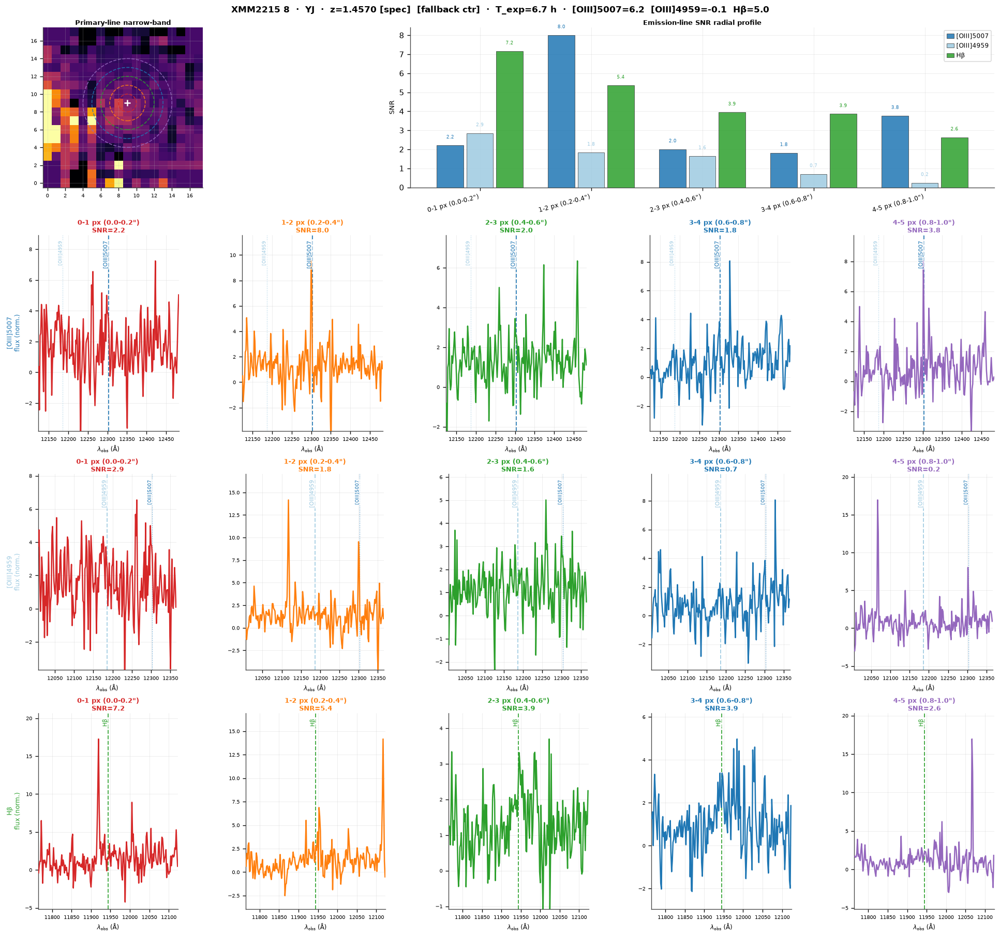

Saved → kmos_snr_annuli_oiii_detail_XMM2215_8_YJ.pdf


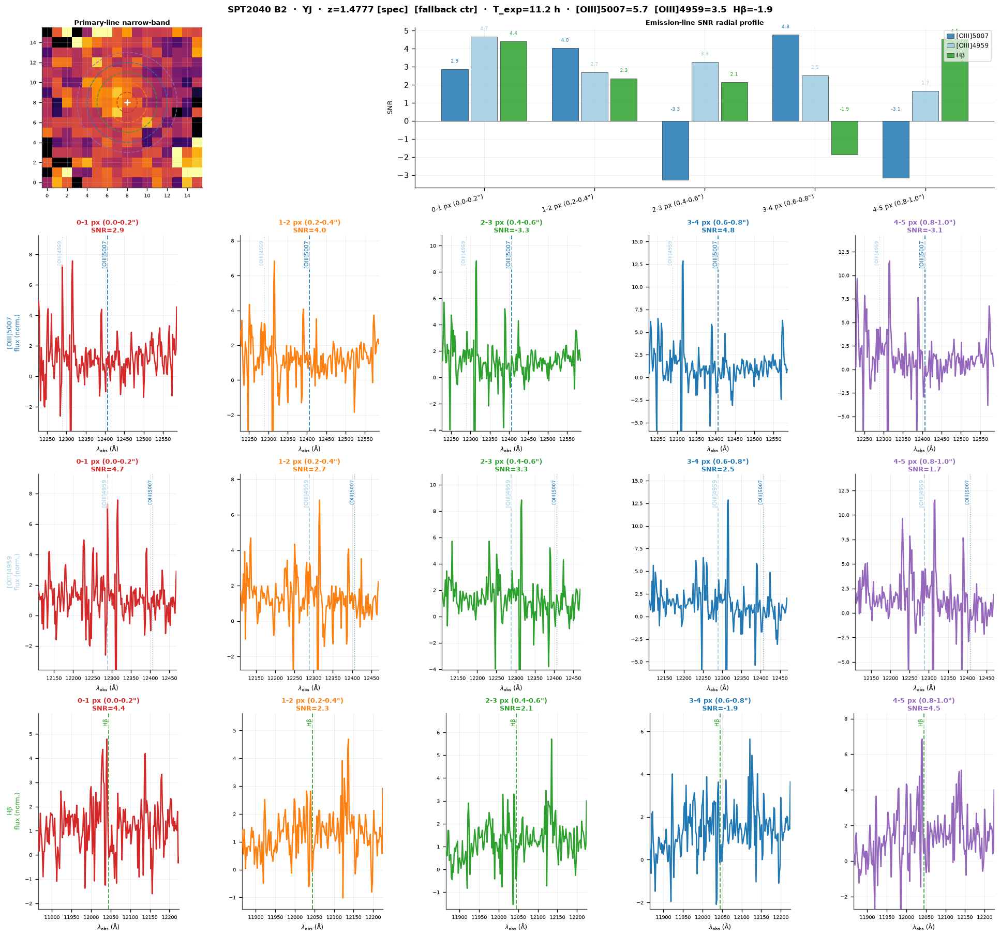

Saved → kmos_snr_annuli_oiii_detail_SPT2040_B2_YJ.pdf


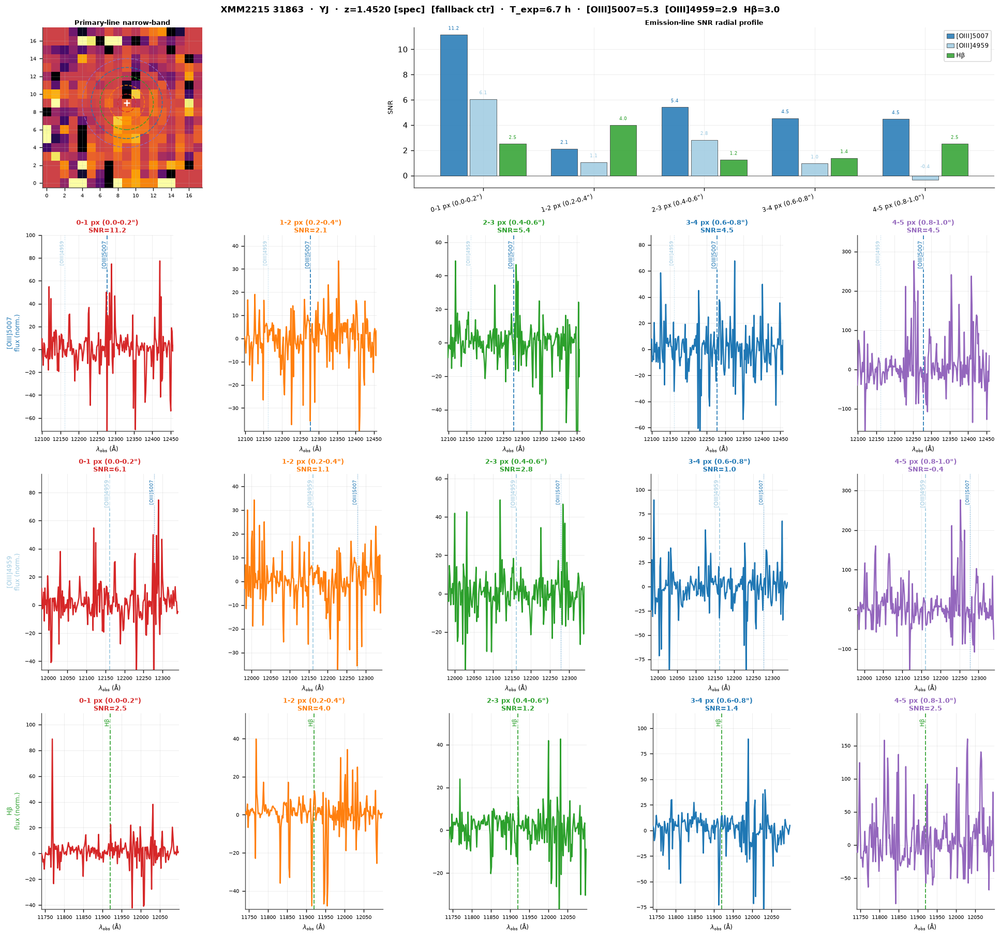

Saved → kmos_snr_annuli_oiii_detail_XMM2215_31863_YJ.pdf


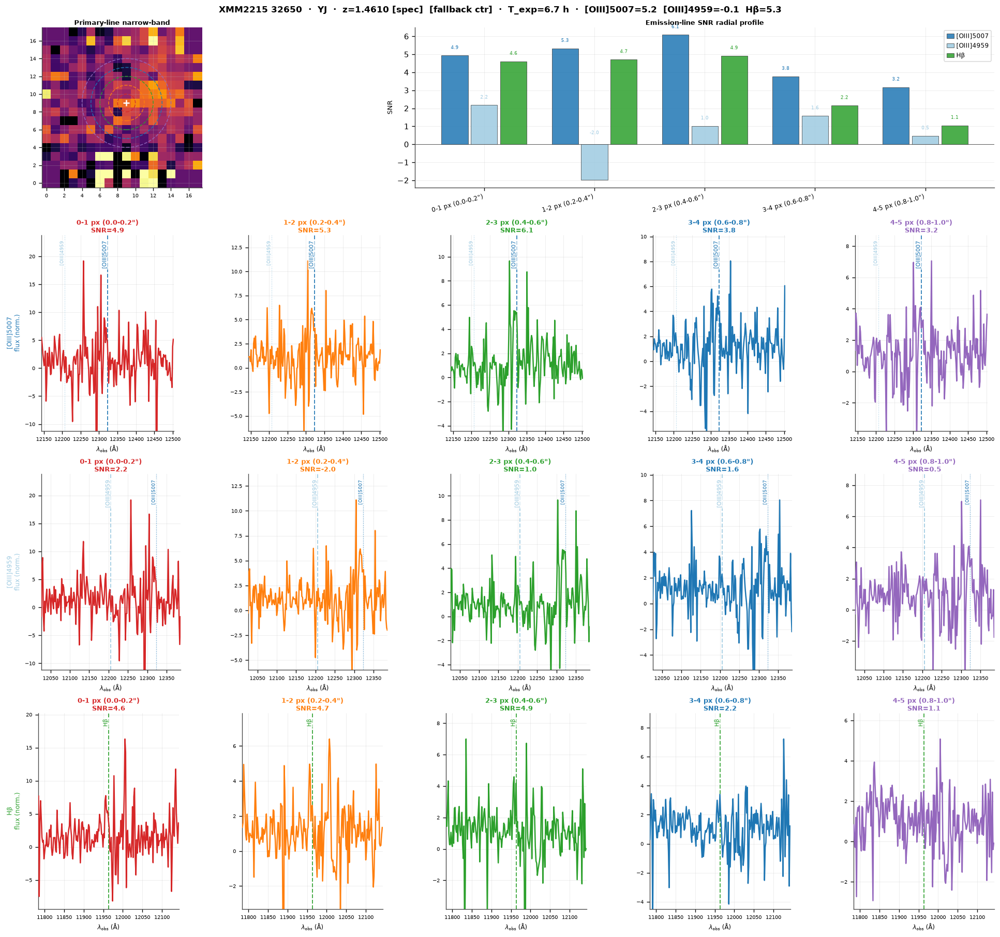

Saved → kmos_snr_annuli_oiii_detail_XMM2215_32650_YJ.pdf


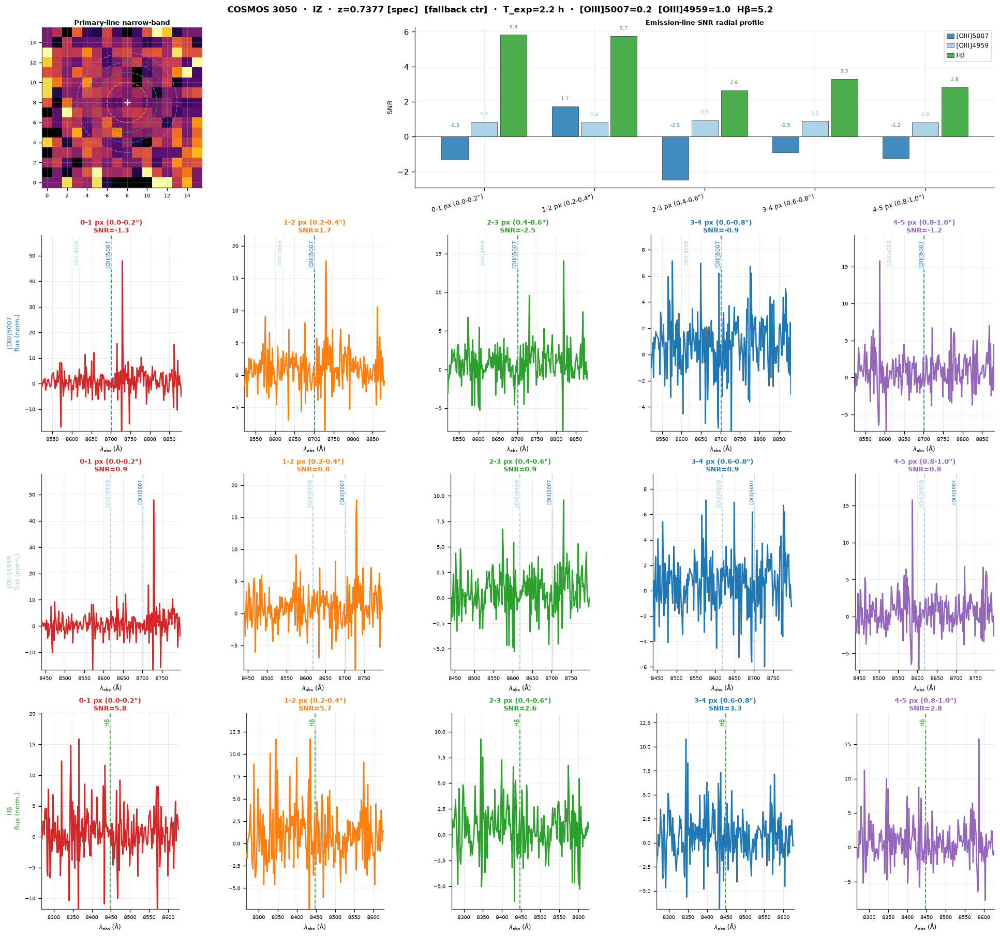

Saved → kmos_snr_annuli_oiii_detail_COSMOS_3050_IZ.pdf


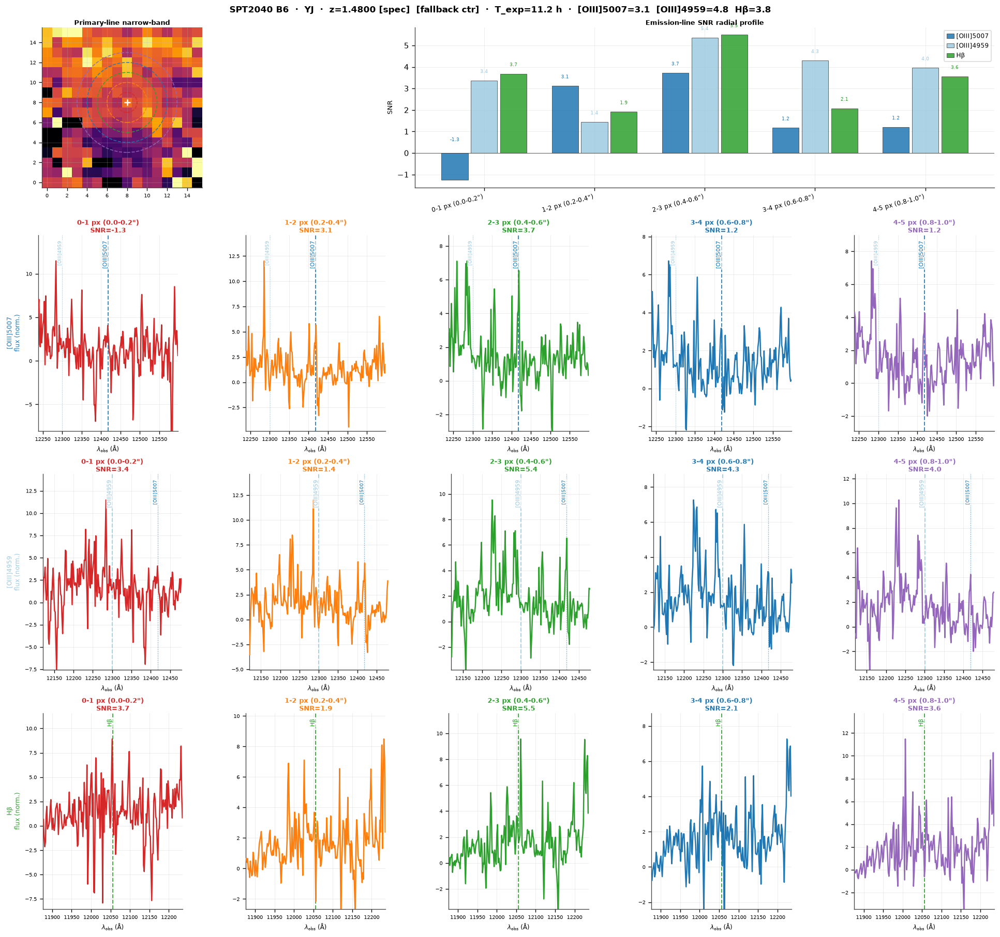

Saved → kmos_snr_annuli_oiii_detail_SPT2040_B6_YJ.pdf


In [9]:
# ── Galaxies with no Hα in wavelength range ────────────────────────────────────
non_ha = [
    e for e in detected
    if not (e['wave'].min() < HA_REST * (1.0 + e['z']) < e['wave'].max())
    and any(
        any(np.isfinite(v) and v > 0 for v in e['ann_snrs_by_line'].get(lbl, []))
        for lbl, *_ in EMISSION_LINES if lbl != 'Hα'
    )
]
non_ha.sort(
    key=lambda x: x['snr_central'] if np.isfinite(x.get('snr_central', np.nan)) else -np.inf,
    reverse=True,
)
print(f"Galaxies with OIII/Hβ but no Hα in range: {len(non_ha)}")

LINE_MARKERS_NH = {
    "Hα":          {"[NII]6548": (0.65480, "#ff7f0e", 0.8, ":"),
                    "[NII]6583": (0.65835, "#ff7f0e", 1.1, "--")},
    "[OIII]5007":  {"[OIII]4959": (0.49598, "#9ecae1", 0.8, ":")},
    "[OIII]4959":  {"[OIII]5007": (0.50073, "#1f77b4", 0.8, ":")},
    "Hβ":          {},
}

for e, gal_color in zip(non_ha, PALETTE):
    wave = e['wave']
    z    = e['z']

    gal_lines = [
        (lbl, lrest, lcolor, lwh) for lbl, lrest, lcolor, lwh in EMISSION_LINES
        if wave.min() < lrest * (1.0 + z) < wave.max()
    ]
    if not gal_lines:
        continue

    n_spec_rows   = len(gal_lines)
    height_ratios = [1.5] + [1.8] * n_spec_rows
    fig = plt.figure(figsize=(16, 4.5 + n_spec_rows * 3.5), constrained_layout=True)
    fb  = "  [fallback ctr]" if e.get('fallback') else ''
    sbl = e['snr_by_line']
    snr_parts = [
        f"{lbl}={sbl.get(lbl, np.nan):.1f}" if np.isfinite(sbl.get(lbl, np.nan))
        else f"{lbl}=—"
        for lbl, *_ in gal_lines
    ]
    fig.suptitle(
        f"{e['field']} {e['tid']}  ·  {e['band']}  ·  z={z:.4f} [{e['z_type']}]{fb}  ·  "
        f"T_exp={_texp_str(e['total_exptime_s'])}  ·  " + "  ".join(snr_parts),
        fontsize=10, fontweight='bold',
    )

    outer = gridspec.GridSpec(1 + n_spec_rows, 1, figure=fig,
                              height_ratios=height_ratios, hspace=0.45)

    # ── Row 0: image + grouped SNR bars ──────────────────────────────────────
    top_inner = gridspec.GridSpecFromSubplotSpec(
        1, 2, subplot_spec=outer[0], width_ratios=[1, 2.5], wspace=0.30)
    ax_im  = fig.add_subplot(top_inner[0])
    ax_snr = fig.add_subplot(top_inner[1])

    ha_im  = e.get('ha_image')
    cy, cx = e['ctr_ha']
    if ha_im is not None and np.isfinite(ha_im).any():
        fin = ha_im[np.isfinite(ha_im)]
        ax_im.imshow(ha_im, origin='lower', aspect='equal', cmap='inferno',
                     vmin=np.nanpercentile(fin, 5), vmax=np.nanpercentile(fin, 97))
    else:
        ax_im.set_facecolor('#111')
    for i, r_out in enumerate(ANNULUS_EDGES[1:]):
        ax_im.add_patch(plt.Circle((cx, cy), r_out,
                                   fill=False, edgecolor=ANNULUS_COLORS[i],
                                   lw=1.0, ls='--', alpha=0.85))
    ax_im.plot(cx, cy, '+', ms=7, mew=1.5, color='white', zorder=5)
    ax_im.set_title("Primary-line narrow-band", fontsize=8, pad=3)
    ax_im.tick_params(labelsize=6)

    n_gal = len(gal_lines)
    bar_w = 0.8 / max(n_gal, 1)
    xs    = np.arange(n_ann)
    for li, (lbl, lrest, lcolor, lwh) in enumerate(gal_lines):
        snrs   = e['ann_snrs_by_line'].get(lbl, [np.nan]*n_ann)
        offset = (li - (n_gal - 1) / 2) * bar_w
        vals   = [v if np.isfinite(v) else 0 for v in snrs]
        bars   = ax_snr.bar(xs + offset, vals, bar_w * 0.9,
                            color=lcolor, alpha=0.85, edgecolor='#333', lw=0.5,
                            label=lbl, zorder=3)
        for bi, v in enumerate(snrs):
            if not np.isfinite(v):
                bars[bi].set_hatch('//')
                bars[bi].set_edgecolor('#aaa')
                bars[bi].set_alpha(0.4)
            txt  = f"{v:.1f}" if np.isfinite(v) else "—"
            ypos = (v + 0.3) if (np.isfinite(v) and v > 0) else 0.5
            ax_snr.text(xs[bi] + offset, ypos, txt, ha='center', va='bottom',
                        fontsize=5.5, color=lcolor if np.isfinite(v) else '#aaa')
    ax_snr.axhline(0, color='#555', lw=0.6)
    ax_snr.set_xticks(xs)
    ax_snr.set_xticklabels(
        [f"{edges[i]}-{edges[i+1]} px ({edges[i]*SPAXEL_SCALE:.1f}-{edges[i+1]*SPAXEL_SCALE:.1f}\")"
         for i in range(n_ann)],
        fontsize=7, rotation=15, ha='right',
    )
    ax_snr.set_ylabel("SNR", fontsize=8)
    ax_snr.set_title("Emission-line SNR radial profile", fontsize=8, pad=3)
    ax_snr.legend(fontsize=7, loc='upper right', framealpha=0.7,
                  handlelength=1.2, handletextpad=0.4)

    # ── Rows 1+: per-line × per-annulus spectra ───────────────────────────────
    for row_i, (lbl, lrest, lcolor, lwh) in enumerate(gal_lines):
        lam_obs = lrest * (1.0 + z)
        wlo = lam_obs - ZOOM_HALF
        whi = lam_obs + ZOOM_HALF
        mask = (wave >= wlo) & (wave <= whi)

        bot_inner = gridspec.GridSpecFromSubplotSpec(
            1, n_ann, subplot_spec=outer[1 + row_i], wspace=0.25)

        companions = LINE_MARKERS_NH.get(lbl, {})

        for ai in range(n_ann):
            ax        = fig.add_subplot(bot_inner[ai])
            spec      = e['ann_specs'][ai]
            snrs      = e['ann_snrs_by_line'].get(lbl, [np.nan]*n_ann)
            snr_v     = snrs[ai]
            ann_color = ANNULUS_COLORS[ai]

            if mask.any() and np.isfinite(spec[mask]).any():
                ax.plot(wave[mask] * 1e4, spec[mask], color=ann_color, lw=1.5, zorder=3)
            else:
                ax.text(0.5, 0.5, 'no signal', ha='center', va='center',
                        transform=ax.transAxes, fontsize=8, color='#aaa', style='italic')

            ax.axvline(lam_obs * 1e4, color=lcolor, lw=1.2, ls='--', alpha=0.85, zorder=2)
            ax.text(lam_obs * 1e4, 0.97, lbl,
                    transform=ax.get_xaxis_transform(),
                    rotation=90, ha='right', va='top', fontsize=6.5, color=lcolor,
                    bbox=dict(fc='white', ec='none', alpha=0.6, pad=1))

            for cname, (crest, cc, clw, cls) in companions.items():
                co = crest * (1.0 + z)
                if wlo <= co <= whi:
                    ax.axvline(co * 1e4, color=cc, lw=clw, ls=cls, alpha=0.75, zorder=2)
                    ax.text(co * 1e4, 0.97, cname,
                            transform=ax.get_xaxis_transform(),
                            rotation=90, ha='right', va='top', fontsize=5.5, color=cc,
                            bbox=dict(fc='white', ec='none', alpha=0.6, pad=1))

            vis = spec[mask] if mask.any() else np.array([])
            fv  = vis[np.isfinite(vis)]
            if fv.size:
                ylo_ = np.nanpercentile(fv, 2)
                yhi_ = np.nanmax(fv)
                pad  = 0.18 * max(yhi_ - ylo_, 1e-6)
                ax.set_ylim(ylo_ - pad, yhi_ + pad)
            ax.set_xlim(wlo * 1e4, whi * 1e4)
            ax.tick_params(labelsize=6)
            ax.set_xlabel(r"$\lambda_{\rm obs}$ (Å)", fontsize=7)
            snr_s = f"SNR={snr_v:.1f}" if np.isfinite(snr_v) else "SNR=—"
            ax.set_title(
                f"{edges[ai]}-{edges[ai+1]} px "
                f"({edges[ai]*SPAXEL_SCALE:.1f}-{edges[ai+1]*SPAXEL_SCALE:.1f}\")\n{snr_s}",
                fontsize=7.5, color=ann_color, pad=3,
            )
            if ai == 0:
                ax.set_ylabel(f"{lbl}\nflux (norm.)", fontsize=7, color=lcolor)

    fname = f"kmos_snr_annuli_oiii_detail_{e['field']}_{e['tid']}_{e['band']}.pdf"
    plt.savefig(fname, bbox_inches='tight')
    plt.show()
    print(f"Saved → {fname}")
